# XANES + PDF Bond Length Prediction

This notebook demonstrates a complete SpectraScope workflow for predicting
Ti–O bond length from simulated XANES and pair distribution function (PDF) spectra
of Ti-oxide structures.

**Data source:** Materials Project database + Na Narong *et al.* [1]

**Workflow:**
1. Load Data
2. Featurize spectra (pointwise, polynomial, CDF, CWT, PCA, feature agglomeration)
3. Combine multi-modal (XANES + PDF)
4. Train models (RF, LCEN, Fused Lasso) with cross-validation
5. Evaluate and visualise performance (Supplementary Figure 2, Main Text Figure 3)
6. Correlation analysis → export CSV files used by GRAPES.ipynb

## Overview

This notebook runs through a simple example of the capabilities of SpectraScope.
The imported data is simulated XANES and PDF of Ti-oxide structures from the
Materials Project database and Na Narong *et al.* [1].
The target variable is Ti–O bond length (Å).

In [1]:
%load_ext autoreload
%autoreload 2

# Core scientific stack
import numpy as np
import pandas as pd
import copy
import os
import string

# Matplotlib / Seaborn
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import gridspec
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from PIL import Image

# Scikit-learn
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.feature_selection import r_regression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error

# SpectraScope
from spectrascope.SpectraScope import *
from spectrascope.Features import *
from spectrascope.FusedLasso import FusedLasso
from spectrascope.SSPlotting import *
from spectrascope.utils import LCEN_selected_features

# SPA (SmartProcessAnalytics) — required for NLTrans featurisation
import SPA

plt.style.use('../ss.mplstyle')

/Users/amalyajohnson/miniconda3/envs/fin/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/amalyajohnson/miniconda3/envs/fin/lib/python3.11/site-packages/matminer/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [2]:
# ---------------------------------------------------------------------------
# Pretty labels for feature names used in all plots and tables
# ---------------------------------------------------------------------------

PRETTY_LABELS_DICT = {
    'xanes_pointwise_features': 'XANES, Intensity',
    'pdf_pointwise_features': 'PDF, Intensity',
    'xanes_polynomial_featuresall': 'XANES, Polynomial',
    'pdf_polynomial_featuresall': 'PDF, Polynomial',
    'xanes_cdf': 'XANES, CDF',
    'xanes_pca': 'XANES, PCA',
    'pdf_pca': 'PDF, PCA',
    'xanes_featureagg': 'XANES, Clustering',
    'pdf_featureagg': 'PDF, Clustering',
    'xanes_pointwise_features_trans': 'XANES, NLTrans',
    'xanes_pdf_pointwise_features': 'XANES + PDF, Intensity',
    'xanes_pdf_polynomial_featuresall': 'XANES + PDF, Polynomial',
    'xanes_cwt': 'XANES, CWT',
}

# ---------------------------------------------------------------------------
# Utility functions for Figure 3 (Main Text)
# ---------------------------------------------------------------------------

def find_nearest(array, value):
    """Return index of element in ``array`` closest to ``value``."""
    return np.abs(array - value).argmin()


def load_and_resize_image(img_path, max_size=128):
    """Load an image and resize so the largest dimension <= ``max_size``."""
    im = Image.open(img_path)
    w, h = im.size
    scale = min(max_size / w, max_size / h, 1.0)
    new_size = (int(w * scale), int(h * scale))
    return np.asarray(im.resize(new_size, resample=Image.LANCZOS))


def plot_spectral_features_matplotlib(xaxis, raw, selected_features, ax=None, zoom=0.1,
                                      plot_raw=True, plot=True, resize=True):
    """
    Overlay polynomial-basis icons on a raw spectrum at selected feature positions.

    Parameters
    ----------
    xaxis : array-like
        Physical x-axis of the spectrum.
    raw : array-like
        Raw spectrum intensities.
    selected_features : list or array-like
        Feature indices to highlight.
    ax : matplotlib Axes, optional
        Axes to draw on; created if None.
    zoom : float
        Zoom factor for overlaid icons.
    plot_raw : bool
        Whether to draw the raw spectrum line.
    plot : bool
        Whether to overlay feature icons.
    resize : bool
        Whether to resize icon images.

    Returns
    -------
    ax : matplotlib Axes
    centers : np.ndarray  shape (N, 2)  — (feature_id, x_center) pairs
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))

    if plot_raw:
        ax.plot(xaxis, raw, color='black', lw=1)

    temp = SpectralFeatures(xaxis, raw)
    for bins in [4, 5, 10, 20]:
        temp.generate_bins(bins)

    feature_config = [
        (0,   16,  'bin_indices_4',  'const', 4),
        (16,  36,  'bin_indices_5',  'line',  5),
        (36,  76,  'bin_indices_10', 'par',   10),
        (76,  156, 'bin_indices_20', 'cubic', 20),
    ]

    centers = []
    for selected_id in selected_features:
        for id_min, id_max, bin_label, poly_label, num_bins in feature_config:
            if id_min <= selected_id < id_max:
                search_bins = np.linspace(id_min, id_max, num_bins)
                located_bin = np.argwhere(selected_id < search_bins)[0][0]
                bin_mask = getattr(temp, bin_label) == located_bin
                center = np.median(xaxis[bin_mask])
                height_id = find_nearest(xaxis, center)
                height = raw[height_id]

                if plot:
                    img_path = f"../app/static/{poly_label}.png"
                    if not os.path.exists(img_path):
                        print(f"Warning: {img_path} not found.")
                        continue
                    im = load_and_resize_image(img_path) if resize else Image.open(img_path)
                    imagebox = OffsetImage(im, zoom=zoom)
                    ab = AnnotationBbox(imagebox, (center, height), frameon=False)
                    ax.add_artist(ab)

                centers.append((selected_id, center))
                break

    return ax, np.array(centers)


def plot_ss_summary(ss, results_df, save_path=None, add_label='', show_importances=False):
    """
    Assemble Main Text Figure 3: RMSE heatmap, raw spectra with selected features
    highlighted, PCA scatter, CDF overlay, and joint XANES+PDF feature plot.

    Parameters
    ----------
    ss : SpectraScope
    results_df : pd.DataFrame  — rows = features, columns = [RF, LCEN]
    save_path : str, optional  — directory to save the figure
    add_label : str            — prefix for the saved filename
    show_importances : bool    — overlay feature importance curves
    """
    xanes_color = '#2176ff'
    pdf_color = '#d8315b'
    pdf_important_color = '#800016'
    xanes_important_color = '#001242'
    fontsize = 25
    ticklabelsize = 20

    pretty_labels = [PRETTY_LABELS_DICT[ind.replace('_nn', '')] for ind in results_df.T.index]

    fig = plt.figure(figsize=(20, 16), constrained_layout=True)
    gs = gridspec.GridSpec(2, 4, figure=fig, width_ratios=[1.2, 2, 2, 2])
    ax1 = fig.add_subplot(gs[:, 0])
    ax2 = fig.add_subplot(gs[0, 2])
    ax3 = fig.add_subplot(gs[0, 3])
    ax4 = fig.add_subplot(gs[1, 2:])
    ax5 = fig.add_subplot(gs[0, 1])
    ax6 = fig.add_subplot(gs[1, 1])

    # Heatmap
    im = ax1.imshow(results_df.T, cmap='plasma')
    ax1.set_yticks(np.arange(len(pretty_labels)))
    ax1.set_yticklabels(pretty_labels, rotation=45, ha='right')
    ax1.set_xticks([0, 1])
    ax1.set_xticklabels(['RF', 'LCEN'])
    cb1 = fig.colorbar(im, ax=ax1, orientation='horizontal', aspect=5, pad=0.03, location='top')
    cb1.ax.tick_params(labelsize=ticklabelsize)
    cb1.set_label('% BL', fontsize=fontsize)
    thresh_90 = np.percentile(results_df.T.values, 85)
    for (i, j), val in np.ndenumerate(results_df.T):
        txt_color = 'black' if val >= thresh_90 else 'white'
        ax1.text(j, i, f'{val:.3f}', ha='center', va='center', color=txt_color, size=ticklabelsize)
    rows = [0, 0, 0]
    cols = np.argsort(results_df.T['RandomForestRegressor'].values)[:3]
    colors = ['green', 'dodgerblue', 'crimson']
    for r, c, color in zip(rows, cols, colors):
        ax1.plot(r, c - 0.3, color=color, marker='*', markersize=20)

    # PCA scatter
    top_pca = ss.xanes_pca_nn_RandomForestRegressor['selected_features'][:2]
    pca_scatter = ax6.scatter(
        ss.xanes_pca[:, top_pca[0]], ss.xanes_pca[:, top_pca[1]],
        c=ss.nn, cmap='viridis', s=40
    )
    cax = inset_axes(ax6, width="5%", height="30%", loc="upper right", borderpad=1)
    cbar_pca = fig.colorbar(pca_scatter, cax=cax, fraction=0.048, pad=0.02, aspect=5, shrink=0.5)
    cbar_pca.ax.tick_params(labelsize=ticklabelsize - 4)
    cbar_pca.ax.yaxis.set_ticks_position("left")
    cbar_pca.ax.yaxis.set_label_position("left")

    # Mean spectra
    mean_xanes = np.mean(ss.xanes_pointwise_features, axis=0)
    mean_pdf = np.mean(ss.pdf_pointwise_features, axis=0)
    for xane_spec in ss.xanes_pointwise_features:
        ax2.plot(ss.xanes_xaxis, xane_spec, color=xanes_color, alpha=0.01)
    for pdf_spec in ss.pdf_pointwise_features:
        ax3.plot(ss.pdf_xaxis, pdf_spec, color=pdf_color, alpha=0.01)
    ax2.plot(ss.xanes_xaxis, mean_xanes, color='black', linewidth=2)
    ax3.plot(ss.pdf_xaxis, mean_pdf, color='black', linewidth=2)

    # CDF panel
    ax5.plot(ss.xanes_xaxis, mean_xanes, color='black', linewidth=2)
    ax5_twin = ax5.twinx()
    for xane_spec in ss.xanes_cdf:
        ax5_twin.plot(ss.xanes_xaxis, xane_spec, color=xanes_color, alpha=0.01)
    top_xanes_cdf_ids = ss.xanes_cdf_nn_RandomForestRegressor['selected_features']
    for idx in top_xanes_cdf_ids[:3]:
        ax5.vlines(ss.xanes_xaxis[idx], ymin=-0.1, ymax=1.5,
                   linewidth=1.5, colors=xanes_important_color, linestyles='dashed')
    ax5.annotate('', xy=(ss.xanes_xaxis[10], 0.42), xytext=(ss.xanes_xaxis[40], 0.42),
                 arrowprops=dict(arrowstyle='->', lw=2, color='black'))
    ax5_twin.annotate('', xy=(ss.xanes_xaxis[-10], 0.40), xytext=(ss.xanes_xaxis[-40], 0.40),
                      arrowprops=dict(arrowstyle='->', lw=2, color=xanes_color))

    # Polynomial feature icons
    _, xanes_centers = plot_spectral_features_matplotlib(
        ss.xanes_xaxis, mean_xanes,
        ss.xanes_polynomial_featuresall_nn_RandomForestRegressor['selected_features'][:10],
        zoom=0.07, ax=ax2, plot_raw=False, resize=False
    )
    _, pdf_centers = plot_spectral_features_matplotlib(
        ss.pdf_xaxis, mean_pdf,
        ss.pdf_polynomial_featuresall_nn_RandomForestRegressor['selected_features'][:10],
        zoom=0.07, ax=ax3, plot_raw=False, resize=False
    )

    poly_handles = [
        Line2D([0], [0], color='#1f77b4', lw=2, label=r'$a_0$'),
        Line2D([0], [0], color='#2ca02c', lw=2, label=r'$a_1$'),
        Line2D([0], [0], color='#9467bd', lw=2, label=r'$a_2$'),
        Line2D([0], [0], color='#ff7f0e', lw=2, label=r'$a_3$'),
    ]
    ax2.legend(handles=poly_handles, loc='upper right', frameon=False,
               fontsize=ticklabelsize + 2, handlelength=0.9, handletextpad=0.3)

    # XANES + PDF polynomial joint panel
    full_y = np.concatenate((mean_xanes, mean_pdf))
    full_x = np.arange(len(ss.xanes_xaxis) + len(ss.pdf_xaxis))
    _, full_centers = plot_spectral_features_matplotlib(
        full_x, full_y,
        ss.xanes_pdf_polynomial_featuresall_nn_RandomForestRegressor['selected_features'],
        zoom=0.07, ax=ax4, plot_raw=True, plot=True, resize=False
    )

    ax2_twin = ax2.twinx()
    ax3_twin = ax3.twinx()
    ax4_twin = ax4.twinx()

    if show_importances:
        ax2_twin.plot(ss.xanes_xaxis,
                      ss.xanes_pointwise_features_nn_RandomForestRegressor['P'][0].best_estimator_.feature_importances_,
                      color='k')
        ax3_twin.plot(ss.pdf_xaxis,
                      ss.pdf_pointwise_features_nn_RandomForestRegressor['P'][0].best_estimator_.feature_importances_,
                      color='k')
        ax4_twin.plot(ss.xanes_pdf_pointwise_features_nn_RandomForestRegressor['P'][0].best_estimator_.feature_importances_,
                      color='k')

    # Top XANES polynomial features
    top_xanes_ids = ss.xanes_polynomial_featuresall_nn_RandomForestRegressor['selected_features']
    for i, _ in enumerate(top_xanes_ids[:3]):
        center = xanes_centers[i][1]
        nearest = find_nearest(center, ss.xanes_xaxis)
        if not show_importances:
            ax2.vlines(center, ymin=-0.1, ymax=2.5,
                       linewidth=1.5, colors=xanes_important_color, linestyles='dashed')
            ax2_twin.set_yticks([])
            ax4_twin.set_yticks([])
        ax4.vlines(nearest, ymin=-2, ymax=2,
                   linewidth=1.5, colors=xanes_important_color, linestyles='dashed')

    # Top PDF polynomial features
    top_pdf_ids = ss.pdf_polynomial_featuresall_nn_RandomForestRegressor['selected_features']
    for i, _ in enumerate(top_pdf_ids[:3]):
        center = pdf_centers[i][1]
        nearest = find_nearest(center, ss.pdf_xaxis)
        if not show_importances:
            ax3.vlines(center, ymin=-10, ymax=15,
                       linewidth=1.5, colors=pdf_important_color, linestyles='dashed')
            ax3_twin.set_yticks([])
        ax4.vlines(200 + nearest, ymin=-2, ymax=2,
                   linewidth=1.5, colors=pdf_important_color, linestyles='dashed')

    ax4.plot(full_x[:200], full_y[:200], color=xanes_color)
    ax4.plot(full_x[200:], full_y[200:], color=pdf_color)

    if show_importances:
        ax2_twin.set_ylabel('Importance', fontsize=fontsize)
        ax3_twin.set_ylabel('Importance', fontsize=fontsize)
        ax4_twin.set_ylabel('Importance', fontsize=fontsize)

    ax2.set_xlabel('Energy (eV)', fontsize=fontsize)
    ax2.set_ylabel(r'$\mu$ (arb.)', fontsize=fontsize)
    ax5.set_xlabel('Energy (eV)', fontsize=fontsize)
    ax5.set_ylabel(r'$\mu$ (arb.)', fontsize=fontsize)
    ax5_twin.set_ylabel('CDF', fontsize=fontsize)
    ax6.set_xlabel(f'PC {top_pca[0] + 1}', fontsize=fontsize)
    ax6.set_ylabel(f'PC {top_pca[1] + 1}', fontsize=fontsize)
    ax3.set_xlabel(r'r ($\AA$)', fontsize=fontsize)
    ax3.set_ylabel(r'G ($\AA^{-1}$)', fontsize=fontsize)
    ax4.set_xlabel('Feature Index', fontsize=fontsize)
    ax4.set_yticks([])

    ax2.set_ylim(-0.1, 2.5)
    ax3.set_ylim(-10, 15)
    ax4.set_ylim(-2, 2)
    ax2.set_title('XANES, Poly', size=fontsize)
    ax3.set_title('PDF, Poly', size=fontsize)
    ax4.set_title('XANES + PDF, Poly', size=fontsize)
    ax5.set_title('XANES, CDF', size=fontsize)
    ax6.set_title('XANES, PCA', size=fontsize)

    panel_labels = [
        (ax1, 'a.'), (ax5, 'b.'), (ax2, 'd.'),
        (ax3, 'e.'), (ax6, 'c.'), (ax4, 'f.'),
    ]
    for axis, label in panel_labels:
        axis.text(-0.16, 1.03, label, transform=axis.transAxes,
                  fontsize=fontsize + 5, fontweight='bold')

    for ax in [ax1, ax2, ax2_twin, ax3_twin, ax3, ax4, ax4_twin, ax5, ax6, ax5_twin]:
        ax.tick_params(axis='both', labelsize=ticklabelsize)
        ax.xaxis.label.set_size(fontsize)
        ax.yaxis.label.set_size(fontsize)

    fig.legend(
        handles=[
            Line2D([0], [0], color=pdf_important_color, lw=1.5, ls='--',
                   label='PDF Top 3 Important Features'),
            Line2D([0], [0], color=xanes_important_color, lw=1.5, ls='--',
                   label='XANES Top 3 Important Features'),
        ],
        loc='lower center',
        bbox_to_anchor=(0.75, -0.00),
        frameon=False,
        fontsize=ticklabelsize,
    )

    if save_path:
        plt.savefig(f"{save_path}/{add_label}.svg")
        plt.savefig(f"{save_path}/{add_label}.pdf")

### Load Data

Load the XANES and PDF spectra arrays and the corresponding bond-length labels.

In [3]:
fnX = '../tests/test_files/X_testfile.npy'
fny = '../tests/test_files/y_testfile.npy'
X = np.load(fnX)
y = np.load(fny)

print('The shape of the input file is:', X.shape)
print('X[0] accesses the PDF data. X[1] accesses the XANES data.\n')
print('The shape of the label file is:', y.shape)

The shape of the input file is: (2, 821, 200)
X[0] accesses the PDF data. X[1] accesses the XANES data.

The shape of the label file is: (821,)


### Initialize SpectraScope

Create a `SpectraScope` object with both modalities (`pdf`, `xanes`)
and the bond-length target (`nn`).

In [4]:
ss = SpectraScope(X=X, y=y, specnames=['pdf', 'xanes'], yname='nn', random_seed=42)

# Unscaled copy for Fused Lasso (same seed ensures identical splits)
ss_unscaled = SpectraScope(X=X, y=y, specnames=['pdf', 'xanes'], yname='nn', random_seed=42)

### Register Wavelength Axes

Attach physical x-axis values (energy in eV for XANES, distance in Å for PDF)
so that features can be traced back to spectral regions.

In [5]:
ss.add_x_axis(specname='xanes', value=np.linspace(4969.0, 5021.0, 200))
ss.add_x_axis(specname='pdf', value=np.linspace(0, 10, 200))

ss_unscaled.add_x_axis(specname='xanes', value=np.linspace(4969.0, 5021.0, 200))
ss_unscaled.add_x_axis(specname='pdf', value=np.linspace(0, 10, 200))

### Generate Pointwise Features

`add_spectral_feature` with `feat='pointwise_features'` interpolates each
spectrum onto the registered x-axis, producing a fixed-length feature vector.

In [6]:
ss.add_spectral_feature(specname='xanes', feat='pointwise_features', xrange=ss.xanes_xaxis)
ss.add_spectral_feature(specname='pdf', feat='pointwise_features', xrange=ss.pdf_xaxis)

ss_unscaled.add_spectral_feature(specname='xanes', feat='pointwise_features', xrange=ss_unscaled.xanes_xaxis)
ss_unscaled.add_spectral_feature(specname='pdf', feat='pointwise_features', xrange=ss_unscaled.pdf_xaxis)

### Visualize Raw Spectra

Plot the first XANES and PDF spectrum to check data quality.

Text(0, 0.5, 'G(r)')

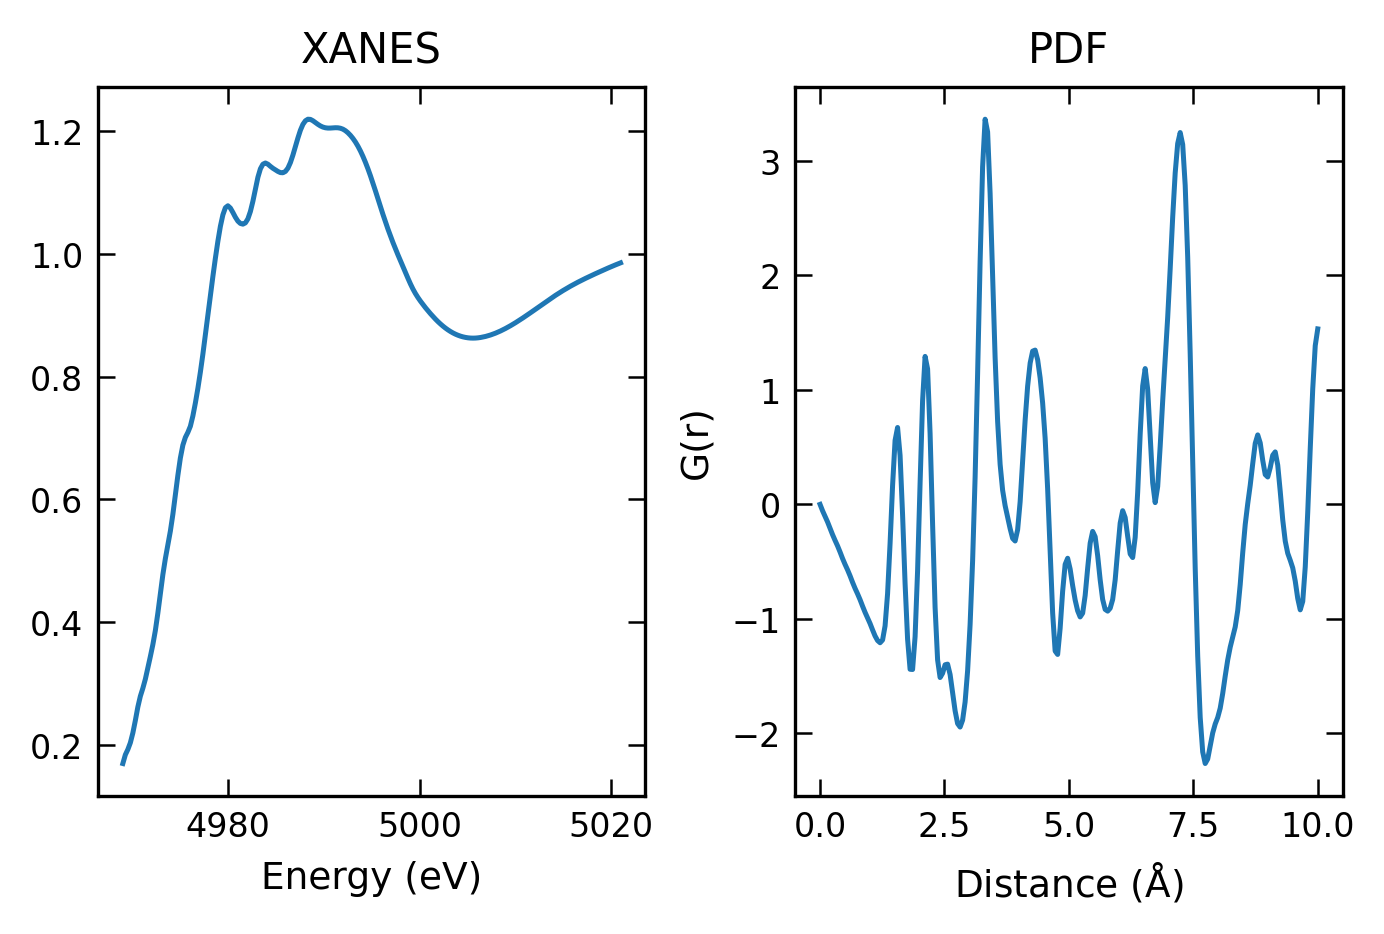

In [7]:
f, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True)
ax1.plot(ss.xanes_xaxis, ss.xanes_pointwise_features[0])
ax2.plot(ss.pdf_xaxis, ss.pdf_pointwise_features[0])
ax1.set_title('XANES')
ax2.set_title('PDF')
ax1.set_xlabel('Energy (eV)')
ax2.set_xlabel(r'Distance ($\AA$)')
ax2.set_ylabel('G(r)')

### Generate Additional Spectral Features

Featurize the XANES data using polynomial fits, feature agglomeration, PCA,
CDF, and CWT.

In [8]:
ss.add_spectral_feature('xanes', 'polynomial_featuresall')
ss.add_spectral_feature('xanes', 'polynomial_featuresN', N=5)
ss.add_spectral_feature('xanes', 'featureagg', n_clusters=10)
ss.add_spectral_feature('xanes', 'pca', n_components=10)
ss.add_spectral_feature('xanes', 'cdf')
ss.add_spectral_feature('xanes', 'cwt')

Text(0.5, 0.98, 'XANES Featurization Schemes')

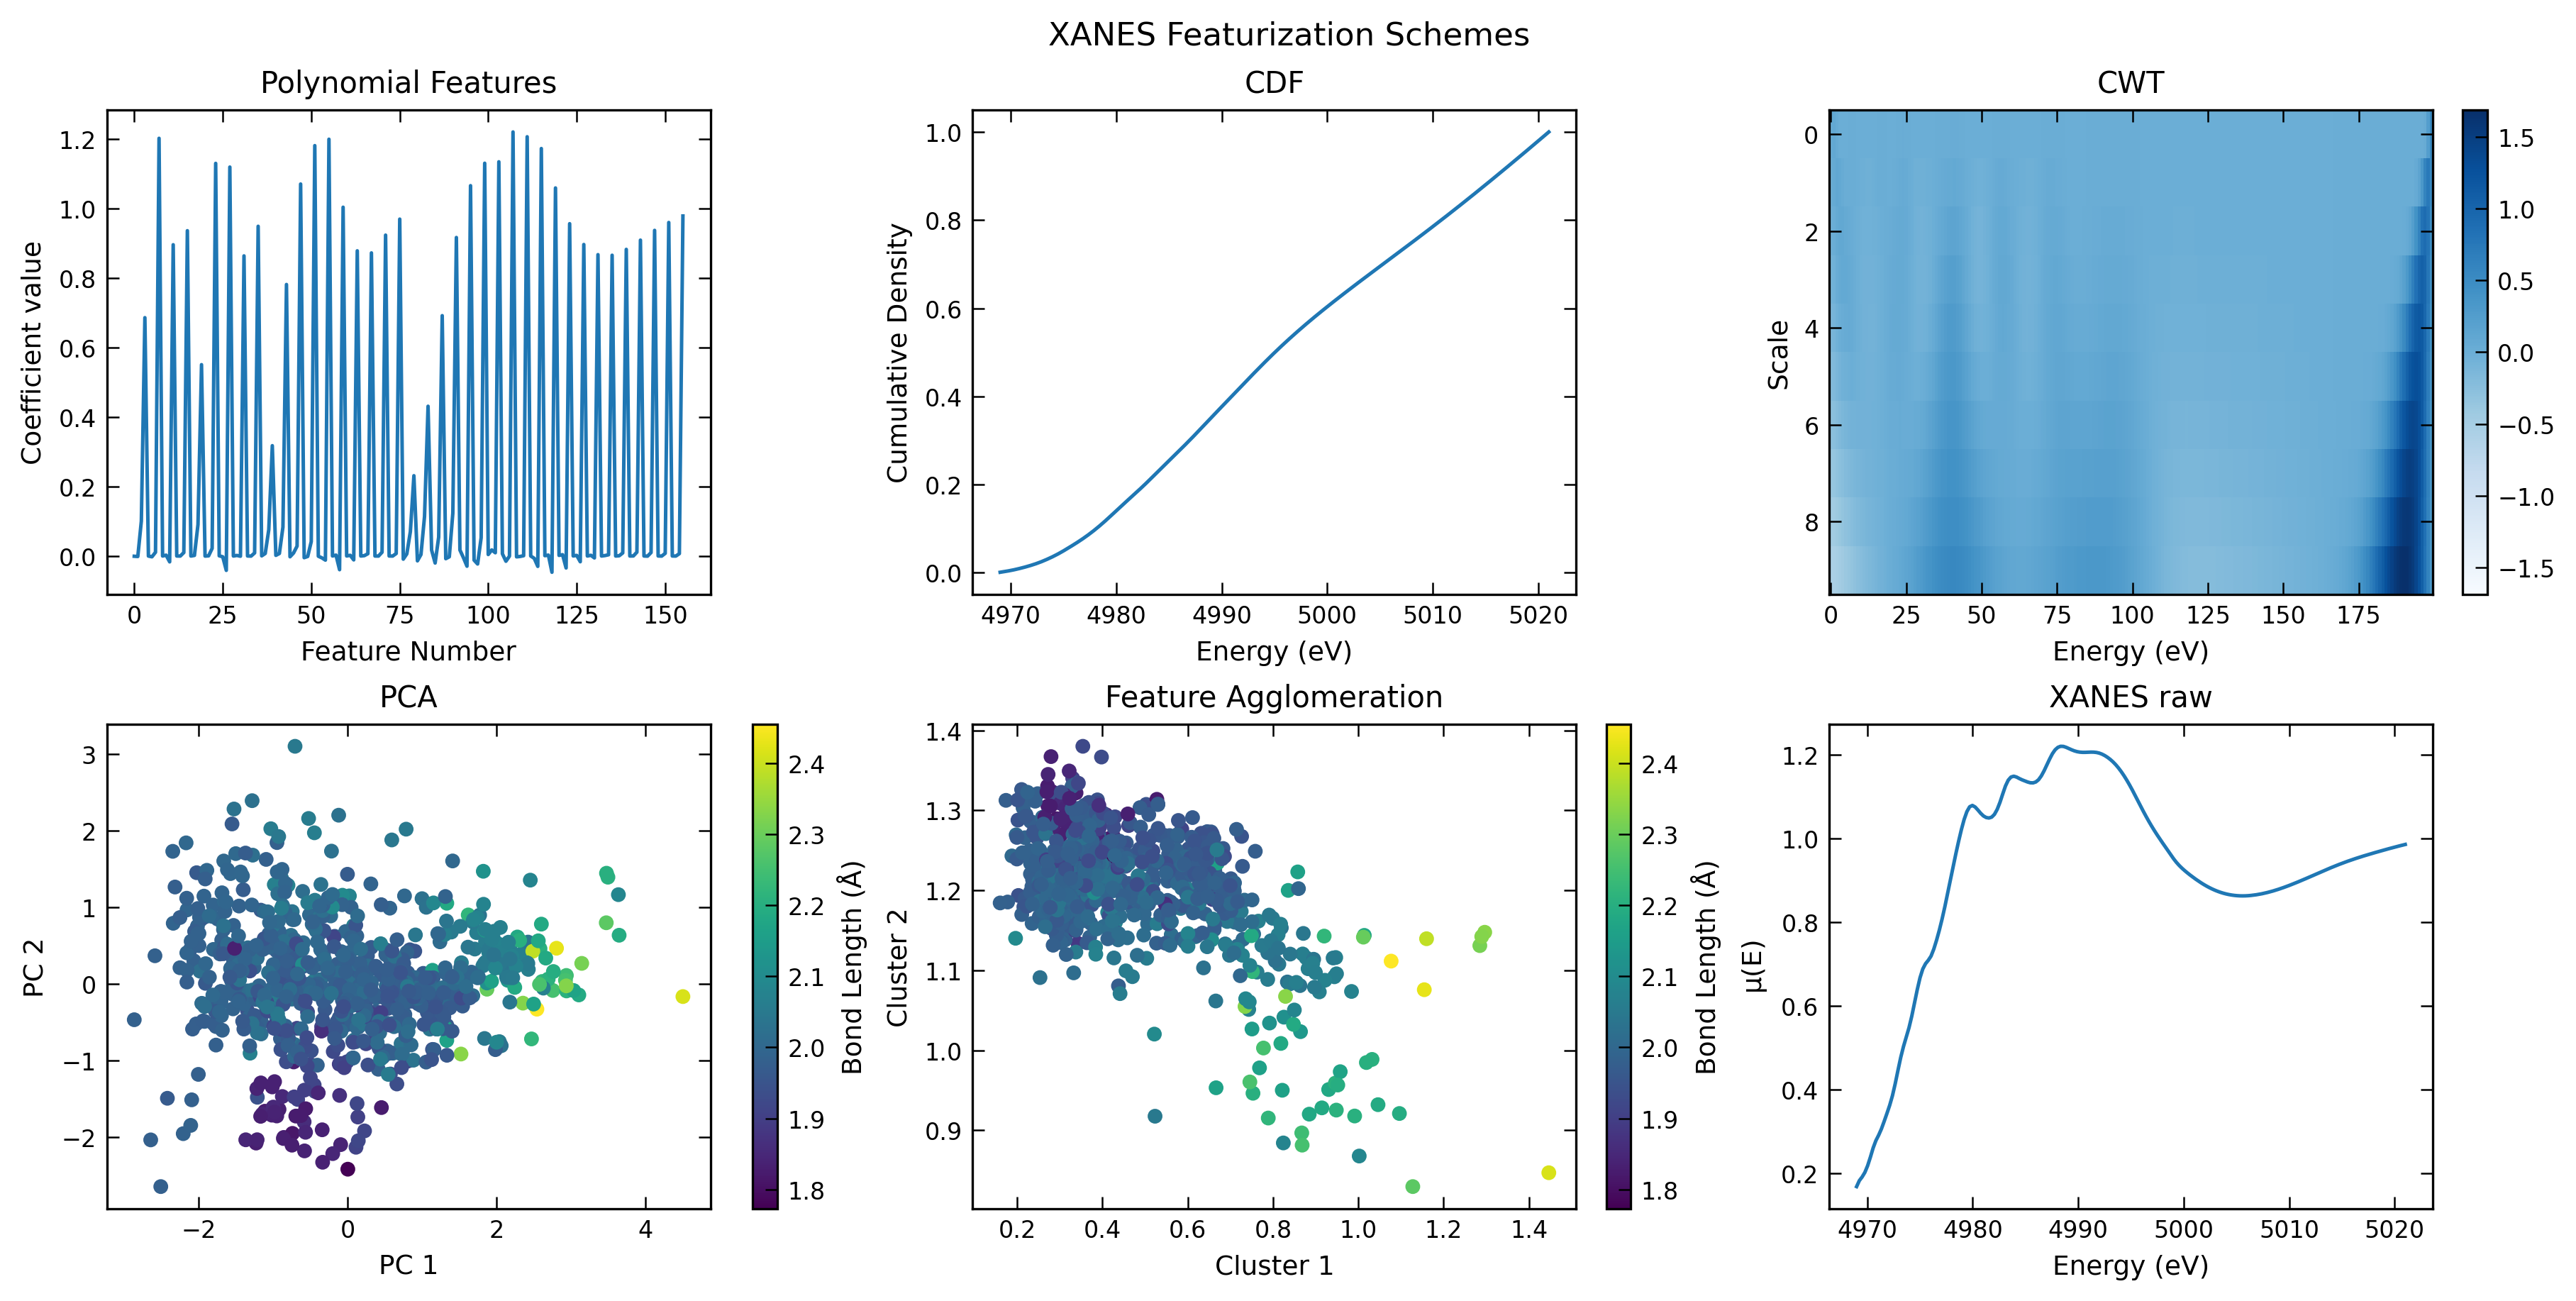

In [9]:
f, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
ax1.plot(np.arange(156), ss.xanes_polynomial_featuresall[0][:-1])
ax2.plot(ss.xanes_xaxis, ss.xanes_cdf[0])

cwt_coefs = ss.xanes_cwt[0]
im = ax3.imshow(cwt_coefs.reshape(10, 200), aspect='auto', cmap='Blues',
                vmax=np.abs(cwt_coefs).max(), vmin=-np.abs(cwt_coefs).max())
f.colorbar(im, ax=ax3)

pc = ax4.scatter(ss.xanes_pca[:, 0], ss.xanes_pca[:, 1], c=ss.nn)
f.colorbar(pc, ax=ax4, label='Bond Length (Å)')
agg = ax5.scatter(ss.xanes_featureagg[:, 0], ss.xanes_featureagg[:, 1], c=ss.nn)
f.colorbar(agg, ax=ax5, label='Bond Length (Å)')
ax6.plot(ss.xanes_xaxis, ss.xanes[0])

ax1.set_title('Polynomial Features');  ax1.set_xlabel('Feature Number');  ax1.set_ylabel('Coefficient value')
ax2.set_title('CDF');                   ax2.set_xlabel('Energy (eV)');       ax2.set_ylabel('Cumulative Density')
ax3.set_title('CWT');                   ax3.set_xlabel('Energy (eV)');       ax3.set_ylabel('Scale')
ax4.set_title('PCA');                   ax4.set_xlabel('PC 1');              ax4.set_ylabel('PC 2')
ax5.set_title('Feature Agglomeration'); ax5.set_xlabel('Cluster 1');         ax5.set_ylabel('Cluster 2')
ax6.set_title('XANES raw');             ax6.set_xlabel('Energy (eV)');       ax6.set_ylabel(r'$\mu(E)$')
f.suptitle('XANES Featurization Schemes')

### Combine Multi-Modal Features

Concatenate XANES and PDF pointwise features into a single joint representation
for multi-modal model training.

In [10]:
ss.combine_feature('xanes_pointwise_features', 'pdf_pointwise_features')

Text(0.5, 0.98, 'XANES + PDF, Combined Features')

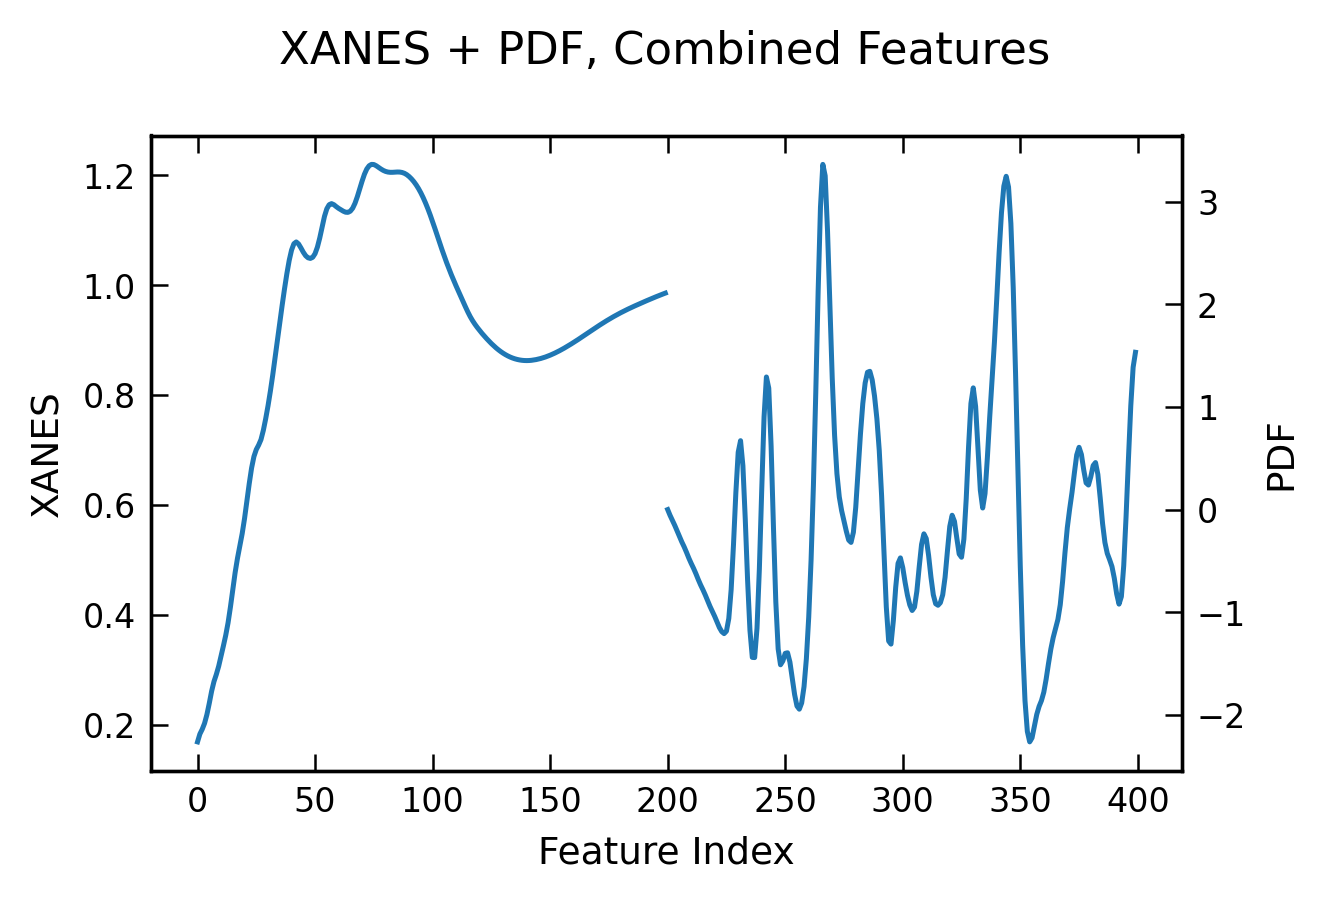

In [11]:
f, ax = plt.subplots(1, 1)
ax_twinx = ax.twinx()
ax.plot(np.arange(200), ss.xanes_pdf_pointwise_features[0][:200])
ax_twinx.plot(np.arange(200, 400), ss.xanes_pdf_pointwise_features[0][200:])
ax.set_xlabel('Feature Index')
ax.set_ylabel('XANES')
ax_twinx.set_ylabel('PDF')
f.suptitle('XANES + PDF, Combined Features')

### Set Up Hyperparameter Grids

Define `kwargs` dicts for each model type: Ridge, Lasso, ElasticNet,
Random Forest, LCEN, and Fused Lasso. Cross-validation uses
`sklearn.model_selection.GridSearchCV`.

In [12]:
ridge_kwargs = {
    'estimator': Ridge(),
    'param_grid': {'alpha': [0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1, 0.2, 0.5, 0.9],
                   'fit_intercept': [True]},
    'refit': True,
    'metric': mean_squared_error,
    'scoring': 'neg_mean_squared_error',
}

lasso_kwargs = {
    'estimator': Lasso(),
    'param_grid': {'alpha': [0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1, 0.2, 0.5, 0.9],
                   'fit_intercept': [True]},
    'refit': True,
    'metric': mean_squared_error,
    'scoring': 'neg_mean_squared_error',
}

en_kwargs = {
    'estimator': ElasticNet(),
    'param_grid': {'alpha': [0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1, 0.2, 0.5, 0.9],
                   'l1_ratio': [0.1, 0.5, 0.9],
                   'fit_intercept': [True]},
    'refit': True,
    'metric': mean_squared_error,
    'scoring': 'neg_mean_squared_error',
}

RF_kwargs = {
    'estimator': RandomForestRegressor(random_state=42),
    'param_grid': {'n_estimators': [50, 100, 200],
                   'criterion': ['squared_error'],
                   'max_depth': [10, 50, None]},
    'refit': True,
    'metric': mean_squared_error,
    'scoring': 'neg_mean_squared_error',
}

lcen_kwargs = {
    'l1_ratio': [0.01, 0.1, 0.3, 0.5, 0.6, 0.99],
    'K_fold': 5,
    'cv_method': 'Kfold',
    'alpha': 5,
    'degree': [1],
    'trans_type': 'poly',
    'LCEN_cutoff': 5e-2,
    'LCEN_interaction': True,
    'scale_X': True,
    'scale_y': True,
}

fused_kwargs = {
    'estimator': FusedLasso(),
    'param_grid': {'alpha': [0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1, 0.2, 0.5, 0.9],
                   'fit_intercept': [True]},
    'refit': True,
    'metric': mean_squared_error,
}

### Nonlinear Feature Transformation

Apply degree-2 polynomial (no interaction terms) to the XANES pointwise features.

In [13]:
ss.transform_feature('xanes_pointwise_features', degree=2, interaction=False)
ss_unscaled.transform_feature('xanes_pointwise_features', degree=2, interaction=False)

### Model Training

Train all model/feature combinations with `ss.do_all`.
Each pair undergoes hyperparameter tuning via 5-fold cross-validation.
Multi-modal features (XANES + PDF concatenated) are also included.

In [14]:
# takes 51m to run on 2026 Macbook Pro M4 max 

feats = {
    'pointwise_features': [{'specname': 'xanes', 'xrange': ss.xanes_xaxis},
                            {'specname': 'pdf',   'xrange': ss.pdf_xaxis}],
    'polynomial_featuresall': [
        {'specname': 'xanes', 'Narr': np.array([4, 5, 10, 20]), 'degree': 3},
        {'specname': 'pdf',   'Narr': np.array([4, 5, 10, 20]), 'degree': 3}],
    'cdf':                   [{'specname': 'xanes'}],
    'pca':                   [{'specname': 'xanes'}, {'specname': 'pdf'}],
    'featureagg':            [{'specname': 'xanes'}, {'specname': 'pdf'}],
    'pointwise_features_trans': [{'specname': 'xanes'}],
}
multi_modal = [
    ('xanes_pointwise_features', 'pdf_pointwise_features'),
    ('xanes_polynomial_featuresall', 'pdf_polynomial_featuresall'),
]

# RF and LCEN on scaled data
ss.do_all(feats, 'nn', 0.20, sk_kwargs=[RF_kwargs], lcen_kwargs=lcen_kwargs,
          multi_modal=multi_modal)

# Fused Lasso on unscaled data (FusedLasso handles its own max-std standardization)
ss_unscaled.do_all(feats, 'nn', 0.20, sk_kwargs=[fused_kwargs], lcen_kwargs=None,
                   multi_modal=multi_modal, scale_X=False)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0393 | Mean relative error = 0.0129
Test set : RMSE = 0.0523 | Mean relative error = 0.0159
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0532 | Mean relative error = 0.0180
Test set : RMSE = 0.0744 | Mean relative error = 0.0233
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its resul

### Random Forest — CV Split Results (Supplementary)

Plot per-fold % RMSE for each hyperparameter combination across all feature sets.
Saves `Figures/XANES_RF_CV.pdf` (SI Figure 2).

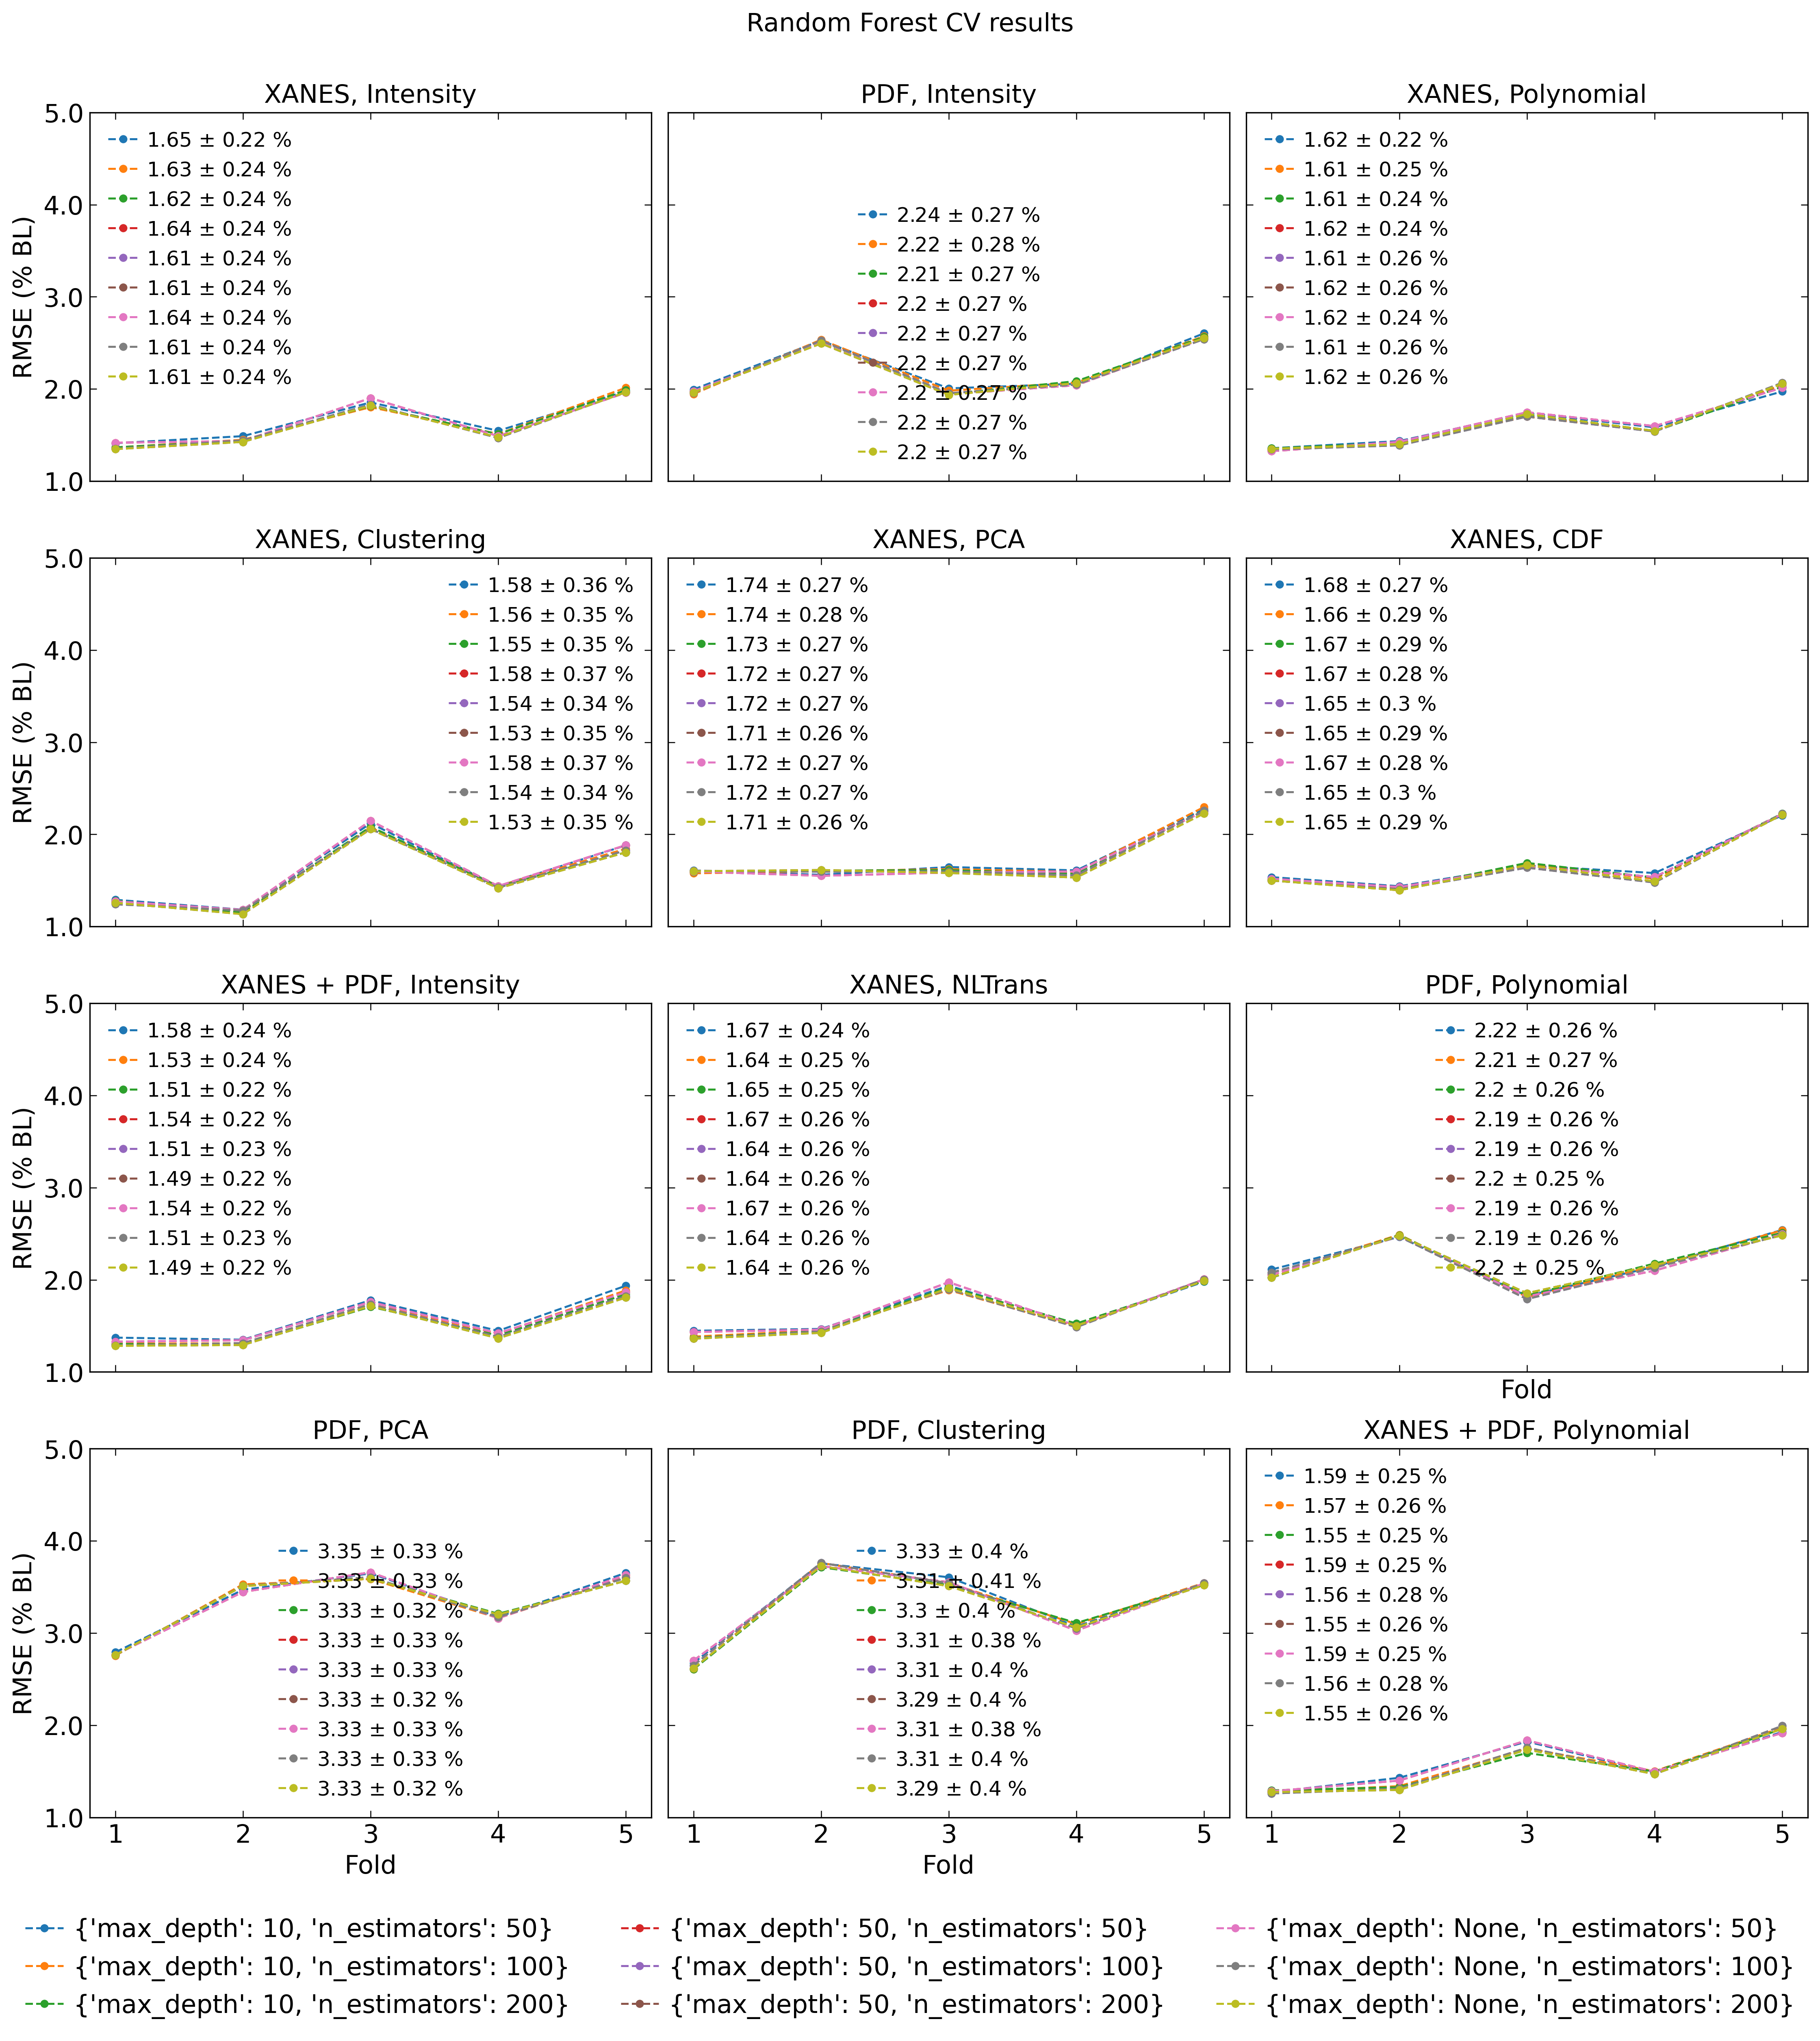

In [15]:
import os
os.makedirs('Figures', exist_ok=True)

f, axs = plt.subplots(4, 3, figsize=(15, 15), sharex=True, sharey=True)
axs = axs.ravel()
i = 0
rf_cv_table = []

for attr_name in ss.generated_features:
    try:
        gs = getattr(ss, f'{attr_name}_nn_RandomForestRegressor')['P'][0]
        cv_results = pd.DataFrame(gs.cv_results_)
        legend_handles = []
        for _, row in cv_results.iterrows():
            scores = row[['split0_test_score', 'split1_test_score', 'split2_test_score',
                          'split3_test_score', 'split4_test_score']].values
            params = {'max_depth': row['params']['max_depth'],
                      'n_estimators': row['params']['n_estimators']}
            legend_handles.append(params)
            result = np.sqrt(np.abs(scores).astype(float)) / np.mean(ss.nn) * 100
            axs[i].plot(np.arange(5), result,
                        label=f"{np.round(np.mean(result), 2)} $\pm$ {np.round(np.std(result), 2)} %",
                        marker='o', linestyle='--')
            axs[i].legend(fontsize=12)
            axs[i].set_title(PRETTY_LABELS_DICT[attr_name], size=15)

        if not cv_results.empty:
            idx_best  = cv_results['mean_test_score'].idxmax()
            idx_worst = cv_results['mean_test_score'].idxmin()
            split_cols = ['split0_test_score', 'split1_test_score', 'split2_test_score',
                          'split3_test_score', 'split4_test_score']
            s_best  = np.sqrt(np.abs(cv_results.loc[idx_best,  split_cols].astype(float))) * 100 / np.mean(ss.nn)
            s_worst = np.sqrt(np.abs(cv_results.loc[idx_worst, split_cols].astype(float))) * 100 / np.mean(ss.nn)

            def param_str(p):
                return '(' + ', '.join([str(p.get(k, '')) for k in ['max_depth', 'n_estimators']]) + ')'

            rf_cv_table.append({
                'Feature': PRETTY_LABELS_DICT.get(attr_name, attr_name),
                'Best (mean \u00b1 std)':  f"{np.mean(s_best):.2f} \u00b1 {np.std(s_best):.2f}",
                'Best hyperparams (depth, N)': param_str(cv_results.loc[idx_best, 'params']),
                'Worst (mean \u00b1 std)': f"{np.mean(s_worst):.2f} \u00b1 {np.std(s_worst):.2f}",
                'Worst hyperparams (depth, N)': param_str(cv_results.loc[idx_worst, 'params']),
            })
        i += 1
    except Exception:
        continue

handles, _ = axs[0].get_legend_handles_labels()
f.legend(handles, legend_handles, loc='lower center', ncols=3, fontsize=15,
         bbox_to_anchor=(0.5, -0.08))

for j, ylabel_ax in enumerate([axs[0], axs[3], axs[6], axs[9]]):
    ylabel_ax.set_ylabel(r'RMSE (% BL)', fontsize=15)
for xlabel_ax in [axs[8], axs[9], axs[10]]:
    xlabel_ax.set_xlabel('Fold', fontsize=15)
for ax in axs:
    ax.set_xticks([0, 1, 2, 3, 4], labels=[1, 2, 3, 4, 5], fontsize=15)
    ax.set_yticks([1, 2, 3, 4, 5], [1.0, 2.0, 3.0, 4.0, 5.0], fontsize=15)

plt.tight_layout()
f.suptitle('Random Forest CV results', fontsize=15, y=1.03)
plt.savefig('Figures/SuppFig1.pdf', dpi=300, bbox_inches='tight')

#### Supplementary Table — RF Hyperparameters

In [16]:
# Supplementary Table — RF hyperparameter summary
# Set print_table = True to display the LaTeX table
print_table = True
if print_table:
    df_cv = pd.DataFrame(rf_cv_table)
    print(df_cv.to_latex(
        index='Feature',
        caption='Table',
        label='Label',
        escape=False,
    ))

\begin{table}
\caption{Table}
\label{Label}
\begin{tabular}{llllll}
\toprule
 & Feature & Best (mean ± std) & Best hyperparams (depth, N) & Worst (mean ± std) & Worst hyperparams (depth, N) \\
\midrule
0 & XANES, Intensity & 1.61 ± 0.24 & (50, 200) & 1.65 ± 0.22 & (10, 50) \\
1 & PDF, Intensity & 2.20 ± 0.27 & (50, 200) & 2.24 ± 0.27 & (10, 50) \\
2 & XANES, Polynomial & 1.61 ± 0.26 & (50, 100) & 1.62 ± 0.24 & (50, 50) \\
3 & XANES, Clustering & 1.53 ± 0.35 & (50, 200) & 1.58 ± 0.37 & (50, 50) \\
4 & XANES, PCA & 1.71 ± 0.26 & (50, 200) & 1.74 ± 0.27 & (10, 50) \\
5 & XANES, CDF & 1.65 ± 0.30 & (50, 100) & 1.68 ± 0.27 & (10, 50) \\
6 & XANES + PDF, Intensity & 1.49 ± 0.22 & (50, 200) & 1.58 ± 0.24 & (10, 50) \\
7 & XANES, NLTrans & 1.64 ± 0.26 & (50, 200) & 1.67 ± 0.26 & (50, 50) \\
8 & PDF, Polynomial & 2.19 ± 0.26 & (50, 50) & 2.22 ± 0.26 & (10, 50) \\
9 & PDF, PCA & 3.33 ± 0.32 & (50, 200) & 3.35 ± 0.33 & (10, 50) \\
10 & PDF, Clustering & 3.29 ± 0.40 & (50, 200) & 3.33 ± 0.40 & (10

### Benchmarking Performance

Visualise model performance using a heatmap comparing % RMSE
across all feature/model combinations.

([<matplotlib.axis.XTick at 0x3ca0ea190>,
 [Text(0.5, 0, 'RF'), Text(1.5, 0, 'LCEN'), Text(2.5, 0, 'Fused Lasso')])

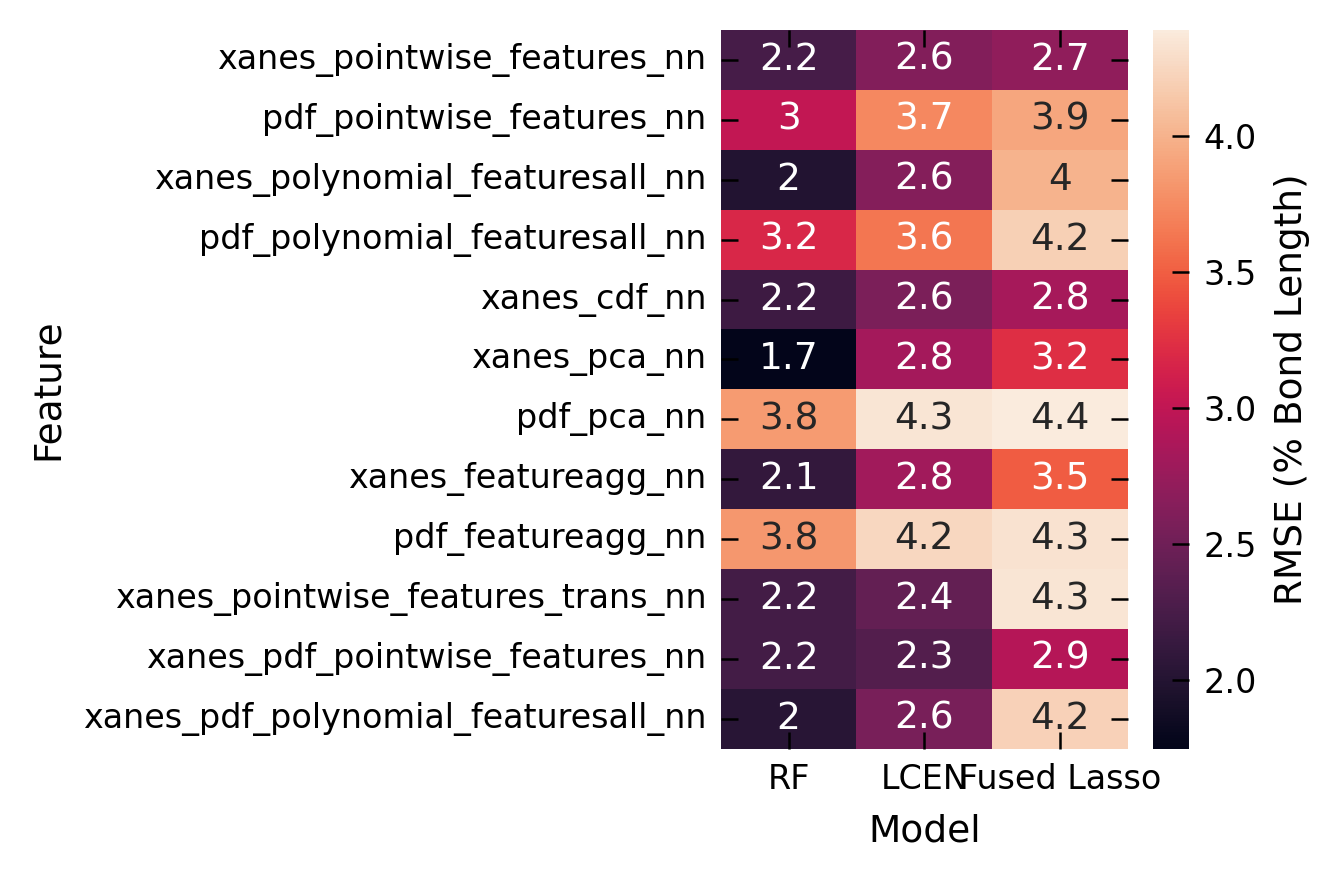

In [17]:
fontsize = 22
ticklabelsize = 18

# Merge best_fits from scaled (RF, LCEN) and unscaled (FusedLasso) objects
combined_fits = pd.DataFrame(ss.best_fits)
combined_fits['FusedLasso'] = pd.DataFrame(ss_unscaled.best_fits)['FusedLasso']

results_df = np.sqrt(combined_fits)[['RandomForestRegressor', 'LCEN', 'FusedLasso']]
results_df = results_df / np.mean(ss.nn) * 100

sns.heatmap(results_df[['RandomForestRegressor', 'LCEN', 'FusedLasso']], annot=True)
plt.xlabel("Model")
plt.ylabel("Feature")
plt.gcf().axes[-1].set_ylabel("RMSE (% Bond Length)")
plt.xticks([0.5, 1.5, 2.5], labels=['RF', 'LCEN', 'Fused Lasso'], ha='center')

### Correlation Analysis

Compute Pearson correlation and mutual information between
the top model-selected features and the bond-length target.
Exports CSV files used by `GRAPES.ipynb` Figure 6.

In [18]:
selected_r = {'RF_r': {}, 'LCEN_r': {}}
ylabel = '_nn'
models = ['_LCEN', '_RandomForestRegressor']

for feat in ss.generated_features:
    for model in models:
        if hasattr(ss, feat + ylabel + model):
            trained_model = getattr(ss, feat + ylabel + model)
            if model == '_LCEN':
                vals, selected_features = LCEN_selected_features(trained_model, -1)
                selected_X = getattr(ss, feat)[:, selected_features]
                r = r_regression(selected_X, ss.nn)
                selected_r['LCEN_r'][feat] = r
                num_features = len(r)
            else:
                feature_importances = trained_model['P'][0].best_estimator_.feature_importances_
                selected_features = np.argsort(feature_importances)[::-1][:num_features]
                selected_X = getattr(ss, feat)[:, selected_features]
                r = r_regression(selected_X, ss.nn)
                selected_r['RF_r'][feat] = r

In [19]:
# Export per-model max/mean correlation vs RMSE — Supplementary Table
temp = pd.DataFrame(results_df[['RandomForestRegressor', 'LCEN']])
temp = temp.rename(index=lambda x: x.replace('_nn', ''))

r_df_max = pd.DataFrame({
    model: {feat: np.max(np.abs(selected_r[model][feat])) for feat in selected_r[model]}
    for model in selected_r
})
r_rmse_max = r_df_max.join(temp, how='inner')
r_rmse_max.columns = ['RF_r', 'LCEN_r', 'RF', 'LCEN']
r_rmse_max = r_rmse_max.rename(PRETTY_LABELS_DICT, axis=0)
r_rmse_max.to_csv('Figures/XANES_rMAX.csv')

r_df_mean = pd.DataFrame({
    model: {feat: np.mean(np.abs(selected_r[model][feat])) for feat in selected_r[model]}
    for model in selected_r
})
r_rmse_mean = r_df_mean.join(temp, how='inner')
r_rmse_mean.columns = ['RF_r', 'LCEN_r', 'RF', 'LCEN']
r_rmse_mean = r_rmse_mean.rename(PRETTY_LABELS_DICT, axis=0)
r_rmse_mean.to_csv('Figures/XANES_rMEAN.csv')

100%|██████████| 14/14 [00:07<00:00,  1.92it/s]


Text(0.5, 1.0, 'XANES, Max r, using all generated features')

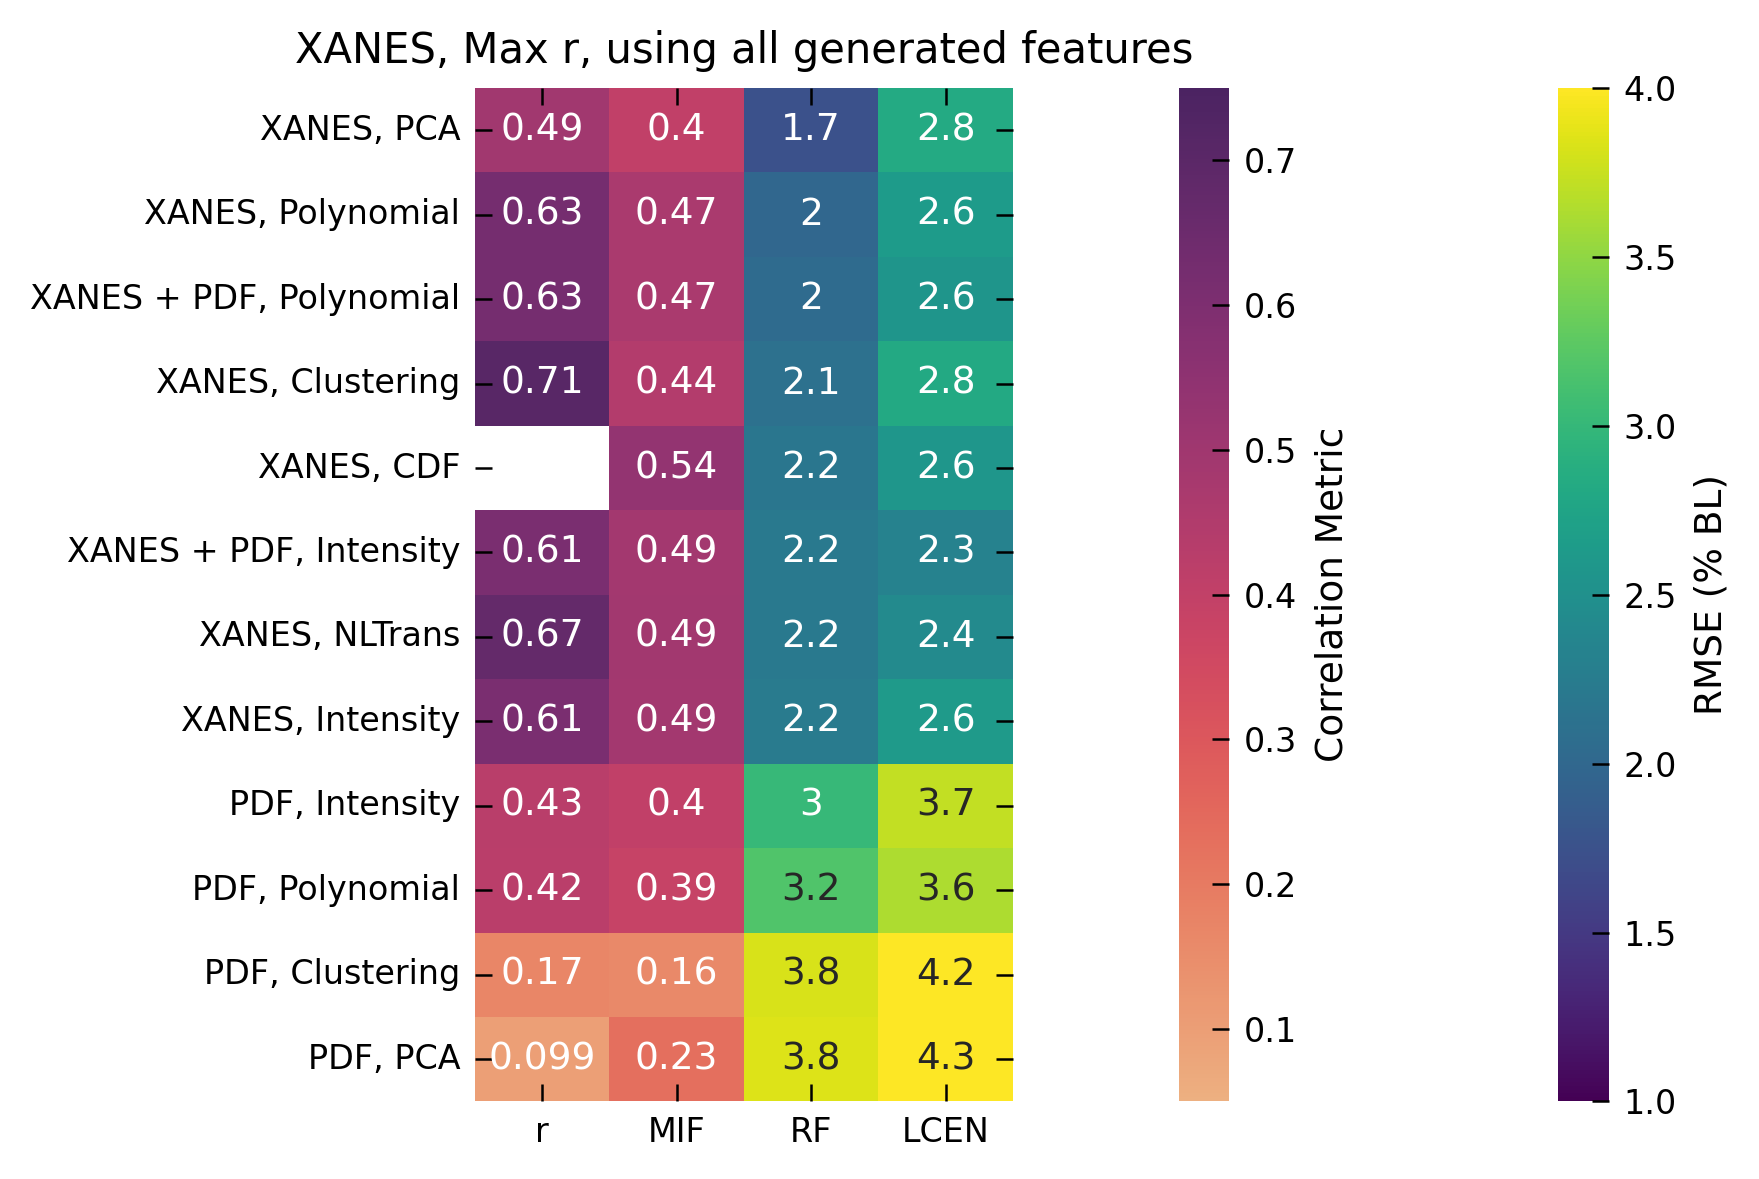

In [20]:
# Pearson r and mutual information across all generated features
corr = ss.pearson_feature_selection('nn', ss.generated_features,
                                    return_vals=True, k=len(ss.generated_features))
corr_df = pd.DataFrame({'r': [np.abs(corr[key]).max() for key in corr]},
                       index=[key for key in corr])

mif = ss.mutual_info_feature_selection('nn', ss.generated_features,
                                       return_vals=True, k=len(ss.generated_features))
mif_df = pd.DataFrame({'MIF': [np.abs(mif[key]).max() for key in mif]},
                      index=[key for key in mif])

merged = corr_df.merge(mif_df, left_index=True, right_index=True)

merged_err = merged.join(temp, how='inner')
merged_err.columns = ['r', 'MIF', 'RF', 'LCEN']
merged_err = merged_err.rename(PRETTY_LABELS_DICT, axis=0)

# Export CSVs used by GRAPES.ipynb Figure 6
merged_err.to_csv('Figures/XANES_corr.csv')
merged_err.to_csv('Figures/XANES_rMAX_all.csv')

# Dual-colormap heatmap: RMSE (viridis) + correlation metric (flare)
cmap1 = plt.get_cmap('viridis').copy(); cmap1.set_under('none')
cmap2 = plt.get_cmap('flare').copy();   cmap2.set_over('none')
f, ax1 = plt.subplots(1, 1, figsize=(6, 4))
ax1 = sns.heatmap(merged_err.sort_values('RF'), vmin=1, vmax=4,
                  annot=True, cmap=cmap1, cbar_kws={'pad': 0.2})
sns.heatmap(merged_err.sort_values('RF'), vmin=0.05, vmax=0.75,
            cmap=cmap2, ax=ax1, cbar_kws={'pad': 0.2})
cbar1 = ax1.collections[0].colorbar; cbar1.set_label('RMSE (% BL)')
cbar2 = ax1.collections[1].colorbar; cbar2.set_label('Correlation Metric')
plt.title('XANES, Max r, using all generated features')

### Model Statistics

Print summary statistics (min/max RMSE) and per-feature breakdown
of MSE, MAE, R², and % RMSE for selected feature sets.

In [21]:
print('% RMSE min:', results_df.min().min(), 'max:', results_df.max().max())
print('RMSE min:', results_df.min().min() * np.mean(ss.nn)/100, 'max:', results_df.max().max() * np.mean(ss.nn)/100)

y_test = ss.nn_test
for feat in ['xanes_pointwise_features_nn', 'xanes_cdf_nn', 'xanes_pca_nn',
             'xanes_polynomial_featuresall_nn']:
    print('----------------------------')
    print('feature:', feat)
    y_pred = ss.__getattribute__(feat + '_RandomForestRegressor')['ypred']
    print('mse:',  mean_squared_error(y_test, y_pred))
    print('mae:',  mean_absolute_error(y_test, y_pred))
    print('R2:',   r2_score(y_test, y_pred))
    print('rmse:', root_mean_squared_error(y_test, y_pred))
    print(' % rmse mean bond length:',
          root_mean_squared_error(y_test, y_pred) / np.mean(ss.nn) * 100)

% RMSE min: 1.749488618919764 max: 4.387248706079442
RMSE min: 0.034907861304548884 max: 0.08753956309526956
----------------------------
feature: xanes_pointwise_features_nn
mse: 0.0020010828691928786
mae: 0.02326034221086674
R2: 0.7395373155647038
rmse: 0.0447334647573031
 % rmse mean bond length: 2.2419215773483065
----------------------------
feature: xanes_cdf_nn
mse: 0.001889134747920574
mae: 0.022549042023400006
R2: 0.7541085802699148
rmse: 0.04346417775502689
 % rmse mean bond length: 2.1783083085418427
----------------------------
feature: xanes_pca_nn
mse: 0.0012185587808576212
mae: 0.020136680505442397
R2: 0.8413913306187093
rmse: 0.034907861304548884
 % rmse mean bond length: 1.749488618919764
----------------------------
feature: xanes_polynomial_featuresall_nn
mse: 0.0015773890972767225
mae: 0.02193229345142417
R2: 0.7946856649463112
rmse: 0.039716358056558036
 % rmse mean bond length: 1.9904776118677918


### Main Text Figure 3

Multi-panel summary figure: RMSE heatmap, raw spectra with selected features
highlighted, PCA scatter, CDF overlay, and XANES + PDF joint feature plot.
Saves `Figures/Fig3.pdf`.

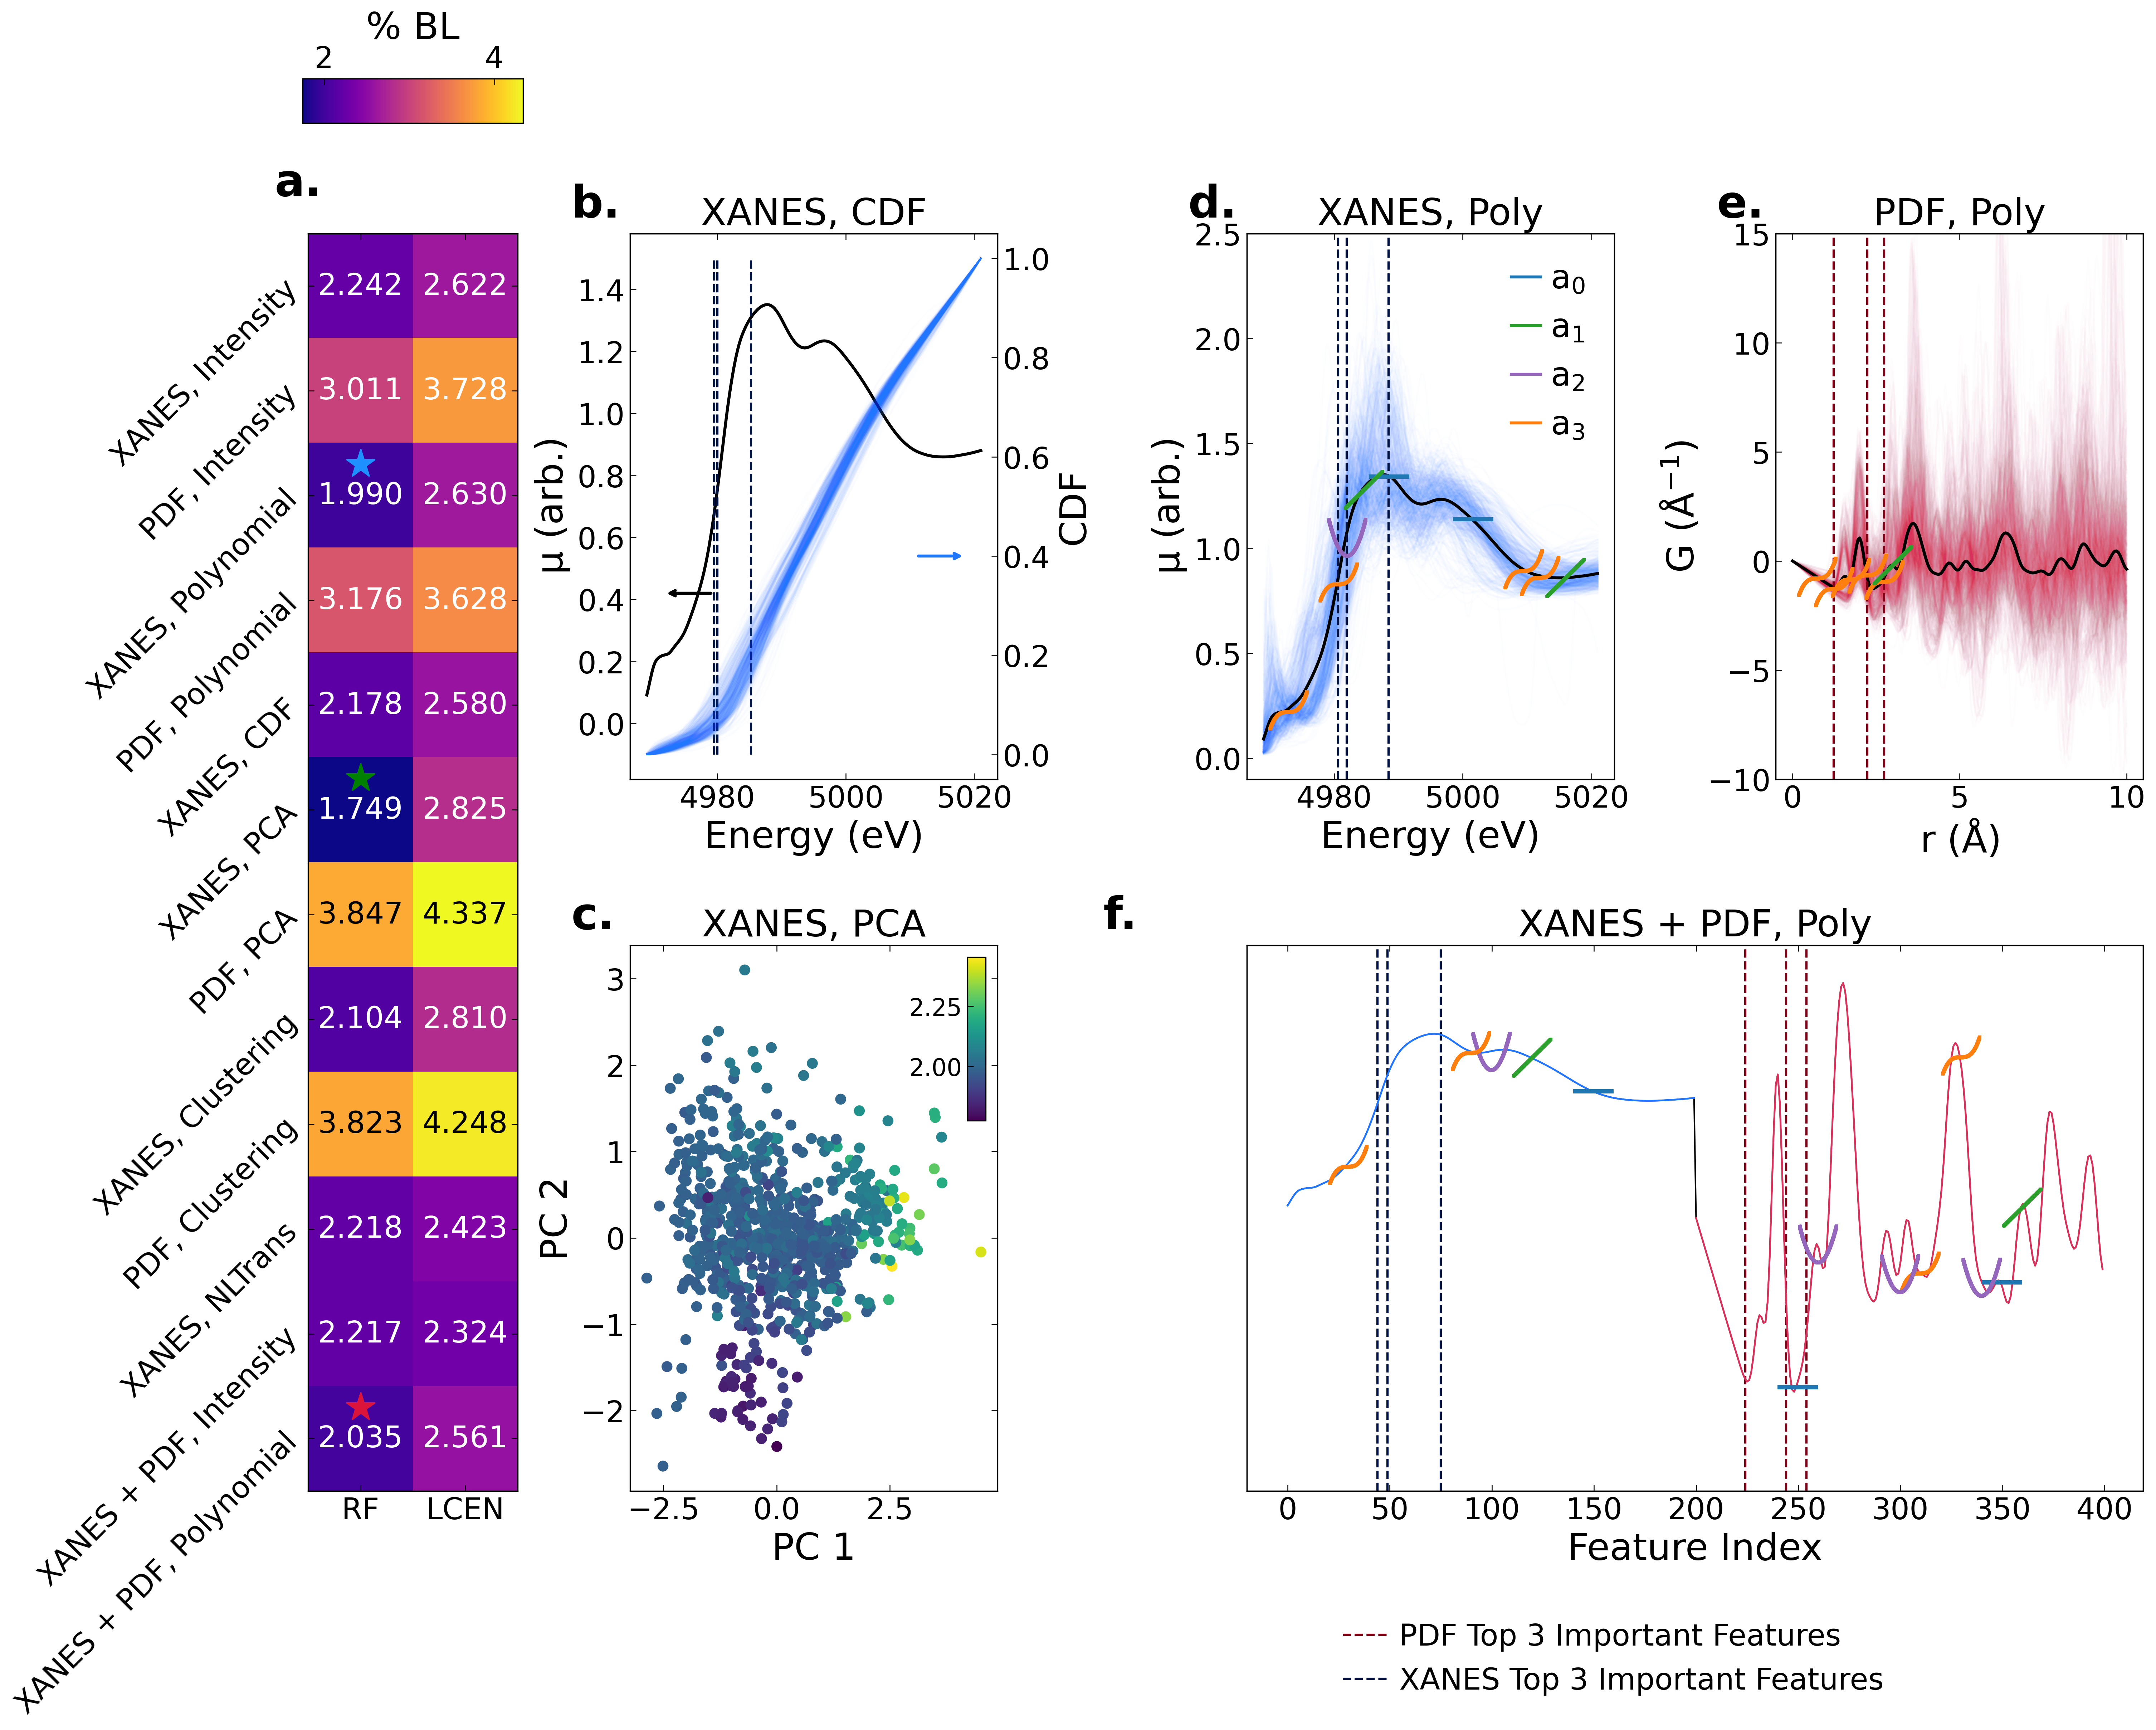

In [22]:
# Main Text Figure 3
results_df_fig3 = (
    np.sqrt(pd.DataFrame(ss.best_fits)[['RandomForestRegressor', 'LCEN']].T)
    / ss.nn.mean() * 100
)
plot_ss_summary(ss, results_df_fig3, add_label='Fig3', save_path='Figures')

### Random Variable Control Experiment

Append a Gaussian random variable as an extra feature to each feature matrix,
then retrain all models. Any feature ranked below the random variable carries no meaningful signal.

In [23]:
# Append a Gaussian random variable to every feature matrix
ss_rv = copy.copy(ss)
ss_rv_unscaled = copy.copy(ss_unscaled)
np.random.seed(42)
for feat in ss.generated_features:
    feat_arr = getattr(ss, feat)
    random_var = np.random.randn(feat_arr.shape[0], 1)
    setattr(ss_rv, feat, np.append(feat_arr, random_var, axis=1))
    # Only append to ss_unscaled if it actually has this feature (Fused Lasso only)
    if hasattr(ss_unscaled, feat):
        setattr(ss_rv_unscaled, feat, np.append(getattr(ss_unscaled, feat), random_var, axis=1))

In [24]:
ss_rv.do_all(feats, 'nn', 0.20, sk_kwargs=[RF_kwargs], lcen_kwargs=lcen_kwargs,
             multi_modal=multi_modal)
ss_rv_unscaled.do_all(feats, 'nn', 0.20, sk_kwargs=[fused_kwargs], lcen_kwargs=None,
                      multi_modal=multi_modal, scale_X=False)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0393 | Mean relative error = 0.0129
Test set : RMSE = 0.0523 | Mean relative error = 0.0159
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0532 | Mean relative error = 0.0180
Test set : RMSE = 0.0744 | Mean relative error = 0.0233
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its resul

In [25]:
rv_importance = {}
for feat in ss_rv.generated_features:
    try:
        rf = getattr(ss_rv, f'{feat}_nn_RandomForestRegressor')['P'][0]
        feature_importances = rf.best_estimator_.feature_importances_
        importance_rv = feature_importances[-1]
        rv_importance[f'{feat}_nn_RandomForestRegressor'] = importance_rv
    except Exception:
        continue
    try:
        model_params = getattr(ss_rv, f'{feat}_nn_LCEN')['model_params']
        n_real_features = getattr(ss_rv, feat).shape[1] - 1
        rv_name = f'x{n_real_features}'
        rv_coef = next((abs(float(val)) for name, val in model_params if name == rv_name), 0.0)
        rv_importance[f'{feat}_nn_LCEN'] = rv_coef
    except Exception:
        continue

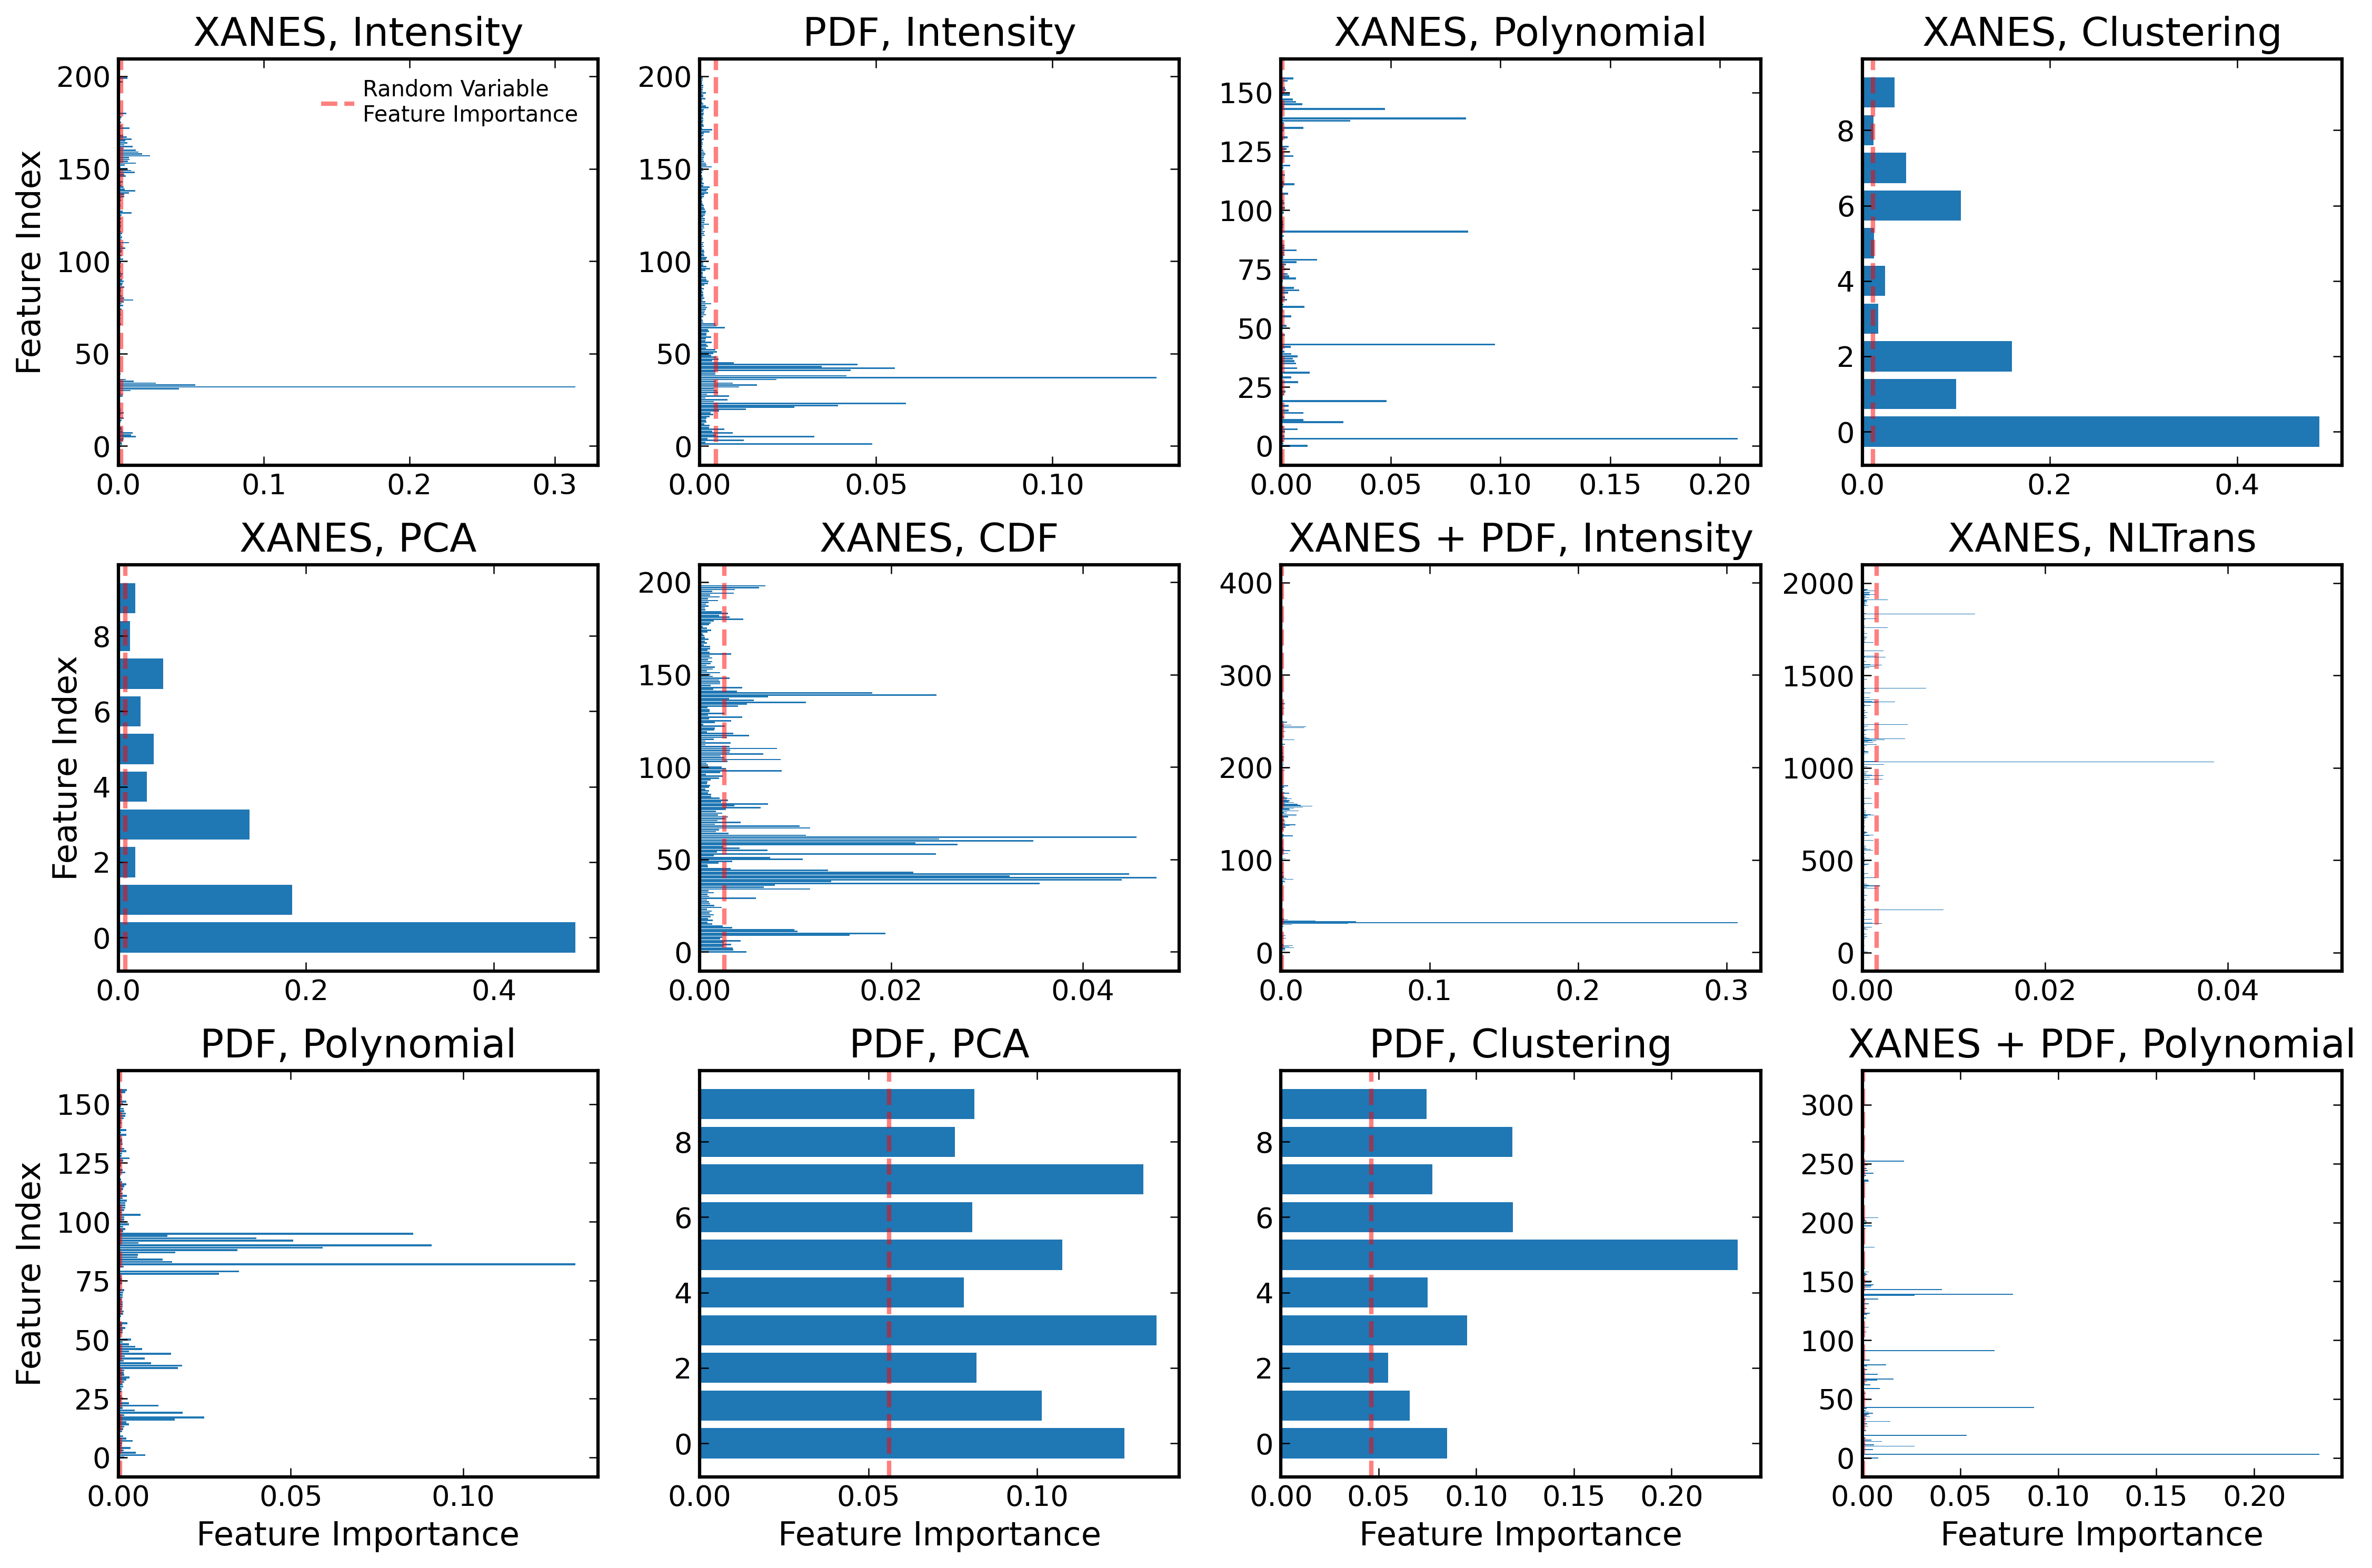

In [26]:
# SI Figure 5 — RF Feature Importance
attr_list, importances_list = [], []
for attr_name in ss.generated_features:
    try:
        gs = getattr(ss, f'{attr_name}_nn_RandomForestRegressor')['P'][0]
        importances_list.append(gs.best_estimator_.feature_importances_)
        attr_list.append(attr_name)
    except Exception:
        continue

n_attrs = len(attr_list)
fig, axs = plt.subplots(3, n_attrs // 3, figsize=(15, 10),
                        sharey=False, constrained_layout=True)
axs = axs.ravel()

for i, (attr_name, feature_importances) in enumerate(zip(attr_list, importances_list)):
    ax = axs[i]
    ax.barh(range(len(feature_importances)), feature_importances)
    ymin, ymax = ax.get_ylim()
    ax.vlines(rv_importance[f'{attr_name}_nn_RandomForestRegressor'], ymin, ymax,
              color='r', linestyle='--', linewidth=2, alpha=0.5,
              label='Random Variable\nFeature Importance')
    ax.set_ylim(ymin, ymax)
    ax.set_title(PRETTY_LABELS_DICT[attr_name], fontsize=18)
    ax.tick_params(axis='both', labelsize=13)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

axs[0].legend(fontsize=10)
for idx in [0, 4, 8]:
    axs[idx].set_ylabel("Feature Index", fontsize=15)
for idx in [8, 9, 10, 11]:
    axs[idx].set_xlabel("Feature Importance", fontsize=15)

plt.tight_layout()
plt.savefig('Figures/SuppFig3.pdf', dpi=300, bbox_inches='tight')

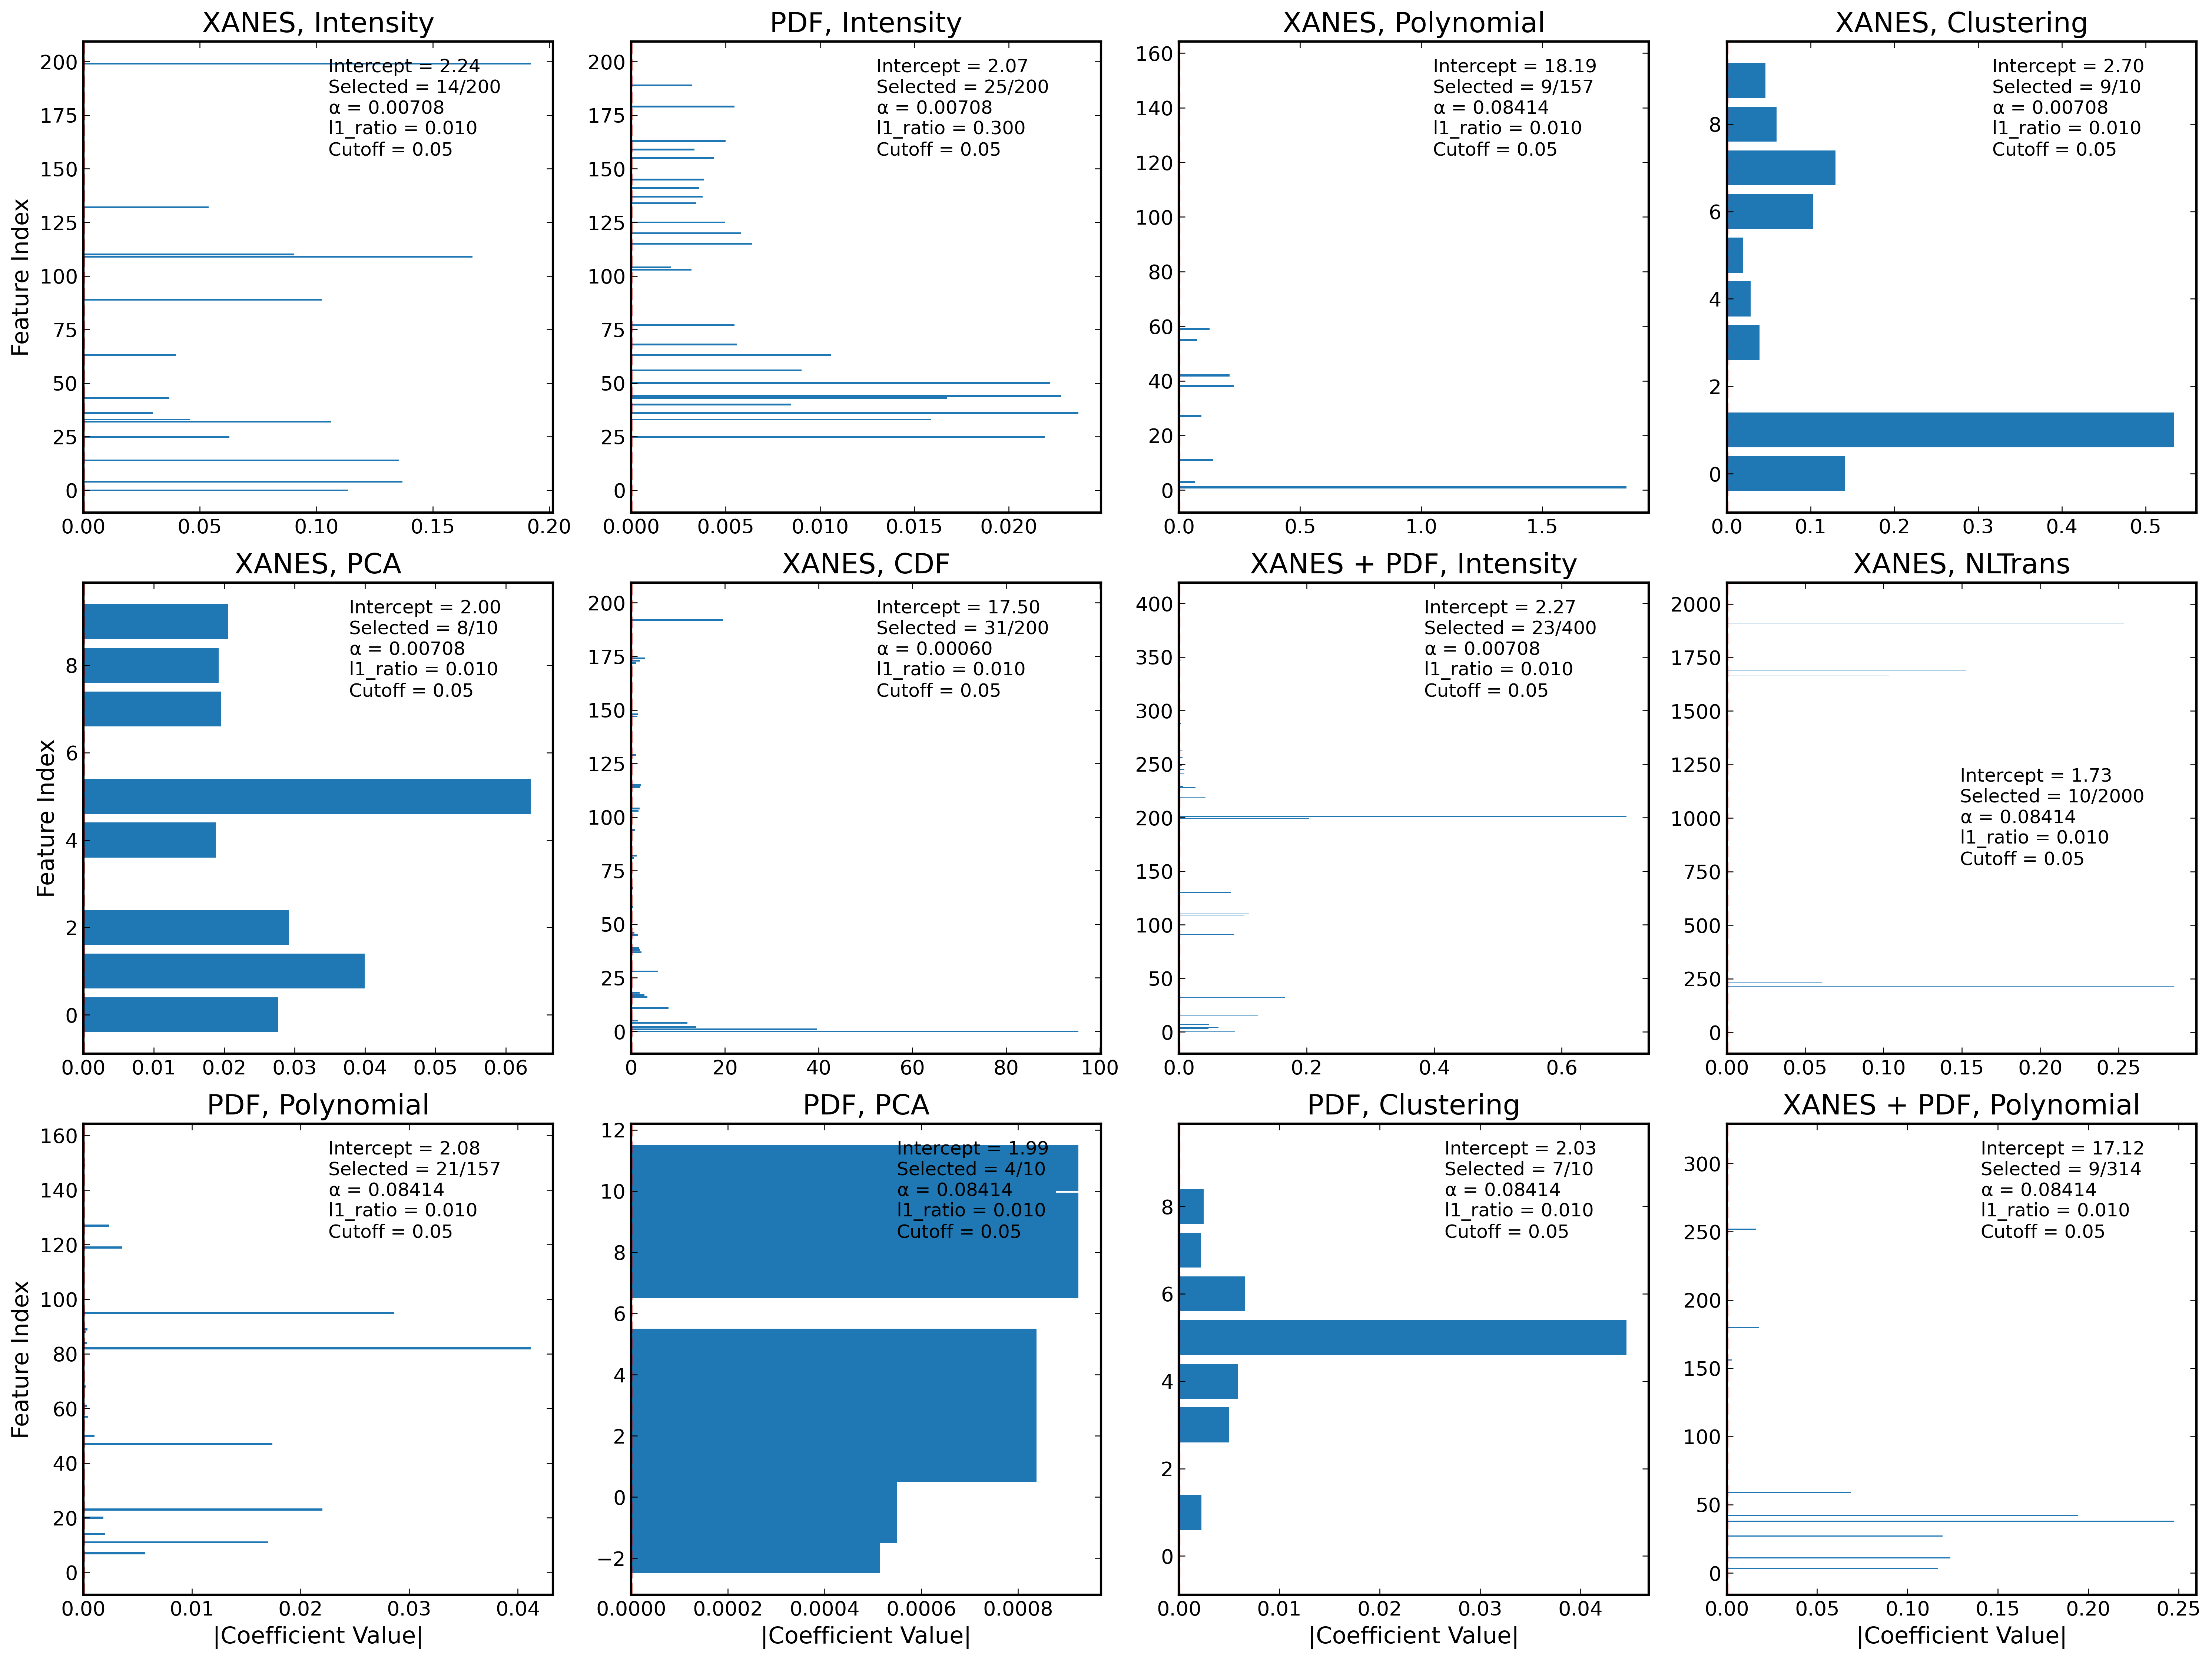

In [27]:
# SI Figure 6 — LCEN Feature Importance
attr_list, importances_list, coef_names = [], [], []
alpha_list, l1_list, cutoff_list = [], [], []

for attr_name in ss.generated_features:
    try:
        lcen_fit = getattr(ss, f'{attr_name}_nn_LCEN')
        model_params = np.array(lcen_fit['model_params'])
        coefs = np.abs(np.array([float(c) for c in model_params[:, 1]]))
        attr_list.append(attr_name)
        importances_list.append(coefs)
        coef_names.append(model_params[:, 0])
        alpha_list.append(lcen_fit['model_hyper']['alpha'])
        l1_list.append(lcen_fit['model_hyper']['l1_ratio'])
        cutoff_list.append(lcen_fit['model_hyper']['cutoff'])
    except Exception:
        continue

fig, axs = plt.subplots(3, 4, figsize=(20, 15), sharey=False, constrained_layout=True)
axs = axs.ravel()

for j, (attr_name, feature_importances) in enumerate(zip(attr_list, importances_list)):
    ax = axs[j]
    par_names = coef_names[j]
    n_features = getattr(ss, attr_name).shape[-1]
    lcen_arr = np.zeros(n_features)
    intercept = 0.0
    for name, val in zip(par_names, feature_importances):
        if name == 'intercept':
            intercept = float(val)
            continue
        lcen_arr[int(name.replace('x', ''))] = float(val)

    rv_val = rv_importance[f'{attr_name}_nn_LCEN']
    idx_above_rv = np.where(lcen_arr > rv_val)[0]
    # ax.barh(idx_above_rv, lcen_arr[idx_above_rv])
    if attr_name=='pdf_pca':
        ax.barh(np.arange(n_features), lcen_arr, height=5)
    else: 
        ax.barh(np.arange(n_features), lcen_arr)
    ymin, ymax = ax.get_ylim()
    if len(idx_above_rv) == 1: 
        ymin -=1 
        ymax +=1 
    ax.vlines(rv_val, ymin, ymax, color='r', linestyle='--', linewidth=2, alpha=0.5,
              label='Random Variable\nCoefficient')
    ax.set_ylim(ymin, ymax)
    ax.set_title(PRETTY_LABELS_DICT[attr_name], fontsize=18)
    ax.tick_params(axis='both', labelsize=13)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

    legend_text = (
        f"Intercept = {intercept:.2f}\n"
        f"Selected = {len(lcen_arr.nonzero()[0])}/{n_features}\n"
        f"$\\alpha$ = {alpha_list[j]:.5f}\n"
        f"l1_ratio = {l1_list[j]:.3f}\n"
        f"Cutoff = {cutoff_list[j]:g}"
    )
    ax.legend([Line2D([0], [0], marker='o', color='w', markerfacecolor='k', markersize=0)],
              [legend_text], fontsize=12, frameon=False, markerfirst=False)

for idx in [0, 4, 8]:
    axs[idx].set_ylabel("Feature Index", fontsize=15)
for idx in [8, 9, 10, 11]:
    axs[idx].set_xlabel("|Coefficient Value|", fontsize=15)

plt.tight_layout()
plt.savefig('Figures/SuppFig4.pdf', dpi=300, bbox_inches='tight')